# 08 · 苍穹外卖：用户下单、订单支付

来源：本地 `讲义.rar / 讲义/day08/苍穹外卖-day08.md` 与 `PPT.rar / PPT/day08-用户下单、订单支付.pptx`，压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章先导入地址簿的七个接口，再把当前用户购物车转成订单和订单明细，最后了解小程序微信支付的预支付、调起支付与服务端回调。沿用前面笔记格式，保留23段讲义代码、表格和配图，对照57页PPT；补充、勘误与验收清单独立标注，配图内嵌可离线阅读。

跟练需要已有用户登录、JWT与BaseContext、菜品套餐、购物车及地址实体。真实微信支付还需要符合平台条件的商户账号、应用关联、有效支付配置与可访问的回调地址；这些条件不等于仅填入课程示例配置。

> **重点勘误。** 原地址按id读写没有校验归属；下单金额直接复制客户端DTO；支付请求固定0.01元且未先检查目标订单；微信支付回调却依赖BaseContext的当前用户id，正常回调中不存在这个登录上下文。回调代码还缺少通知验签及幂等状态更新，不能把解密成功当作全部验证完成。后面逐项说明修正位置。讲义支付YAML的九项示例配置改为填写占位符，其余原代码保留，源讲义未修改。


## 本章路线、接口与状态（补充）

| 顺序 | 功能 | 核心规则 |
| --- | --- | --- |
| 1 | 地址簿 | 当前用户维护自己的地址，默认地址保持唯一 |
| 2 | 下单 | 校验用户、地址、商品和金额，在事务内创建订单与明细并清理已提交购物车 |
| 3 | 发起支付 | 检查自己的待付款订单，按服务端金额创建预支付单 |
| 4 | 支付通知 | 校验微信通知，以商户订单号定位订单，幂等更新支付状态 |

### 接口速查

| 功能 | 方法与后端路径 | 参数来源 |
| --- | --- | --- |
| 新增地址 | `POST /user/addressBook` | JSON地址资料，userId和默认状态由后端控制 |
| 地址列表 | `GET /user/addressBook/list` | 当前登录用户，无userId输入 |
| 默认地址 | `GET /user/addressBook/default` | 当前登录用户 |
| 地址回显 | `GET /user/addressBook/{id}` | Path：id，并校验归属 |
| 修改地址 | `PUT /user/addressBook` | JSON：id与允许修改的地址字段 |
| 删除地址 | `DELETE /user/addressBook?id=...` | Query：id，并校验归属 |
| 设置默认地址 | `PUT /user/addressBook/default` | JSON：目标地址id |
| 用户下单 | `POST /user/order/submit` | JSON OrdersSubmitDTO |
| 发起支付 | `PUT /user/order/payment` | JSON OrdersPaymentDTO，包含orderNumber等约定字段 |
| 支付成功通知 | `POST /notify/paySuccess` | 微信服务端签名通知，无用户JWT；原RequestMapping未限定HTTP方法 |

前九项用户业务接口需要第06章的authentication请求头。通知不是小程序发给后端的“我已支付”请求，应采用微信通知验证规则；原/notify路径不在用户拦截器的/user范围内。

### 两个独立阶段

```text
下单：当前用户 → 地址与购物车校验
    → orders一条（待付款、未支付）
    → order_detail多条 → 清理本次已提交购物车 → 数据库提交

支付：检查该用户的待付款订单 → 微信JSAPI预支付
    → 返回调起支付参数 → 小程序wx.requestPayment
    → 微信服务端通知 → 验签与解密、核对交易
    → 更新订单为待接单、已支付 → 成功确认通知
```

创建本地订单、创建微信预支付单和收到已支付确认是三个不同事件。小程序调起支付成功的展示回调不能直接替代后端付款确认。

### 订单状态与支付状态分开

| 字段 | 课程枚举含义 |
| --- | --- |
| orders.status | 1待付款、2待接单、3已接单、4派送中、5已完成、6已取消 |
| orders.pay_status | 0未支付、1已支付、2退款 |
| orders.pay_method | 1微信、2支付宝；本章代码只对接微信支付 |

订单支付成功时从待付款进入待接单，pay_status改为已支付，记录checkout_time。枚举能表示支付宝不等于已经实现支付宝接口；后续退款、取消和履约状态应有各自规则。

### 四张表的职责

| 表 | 保存内容 |
| --- | --- |
| address_book | 用户可维护的地址资料 |
| shopping_cart | 用户当前待结算商品和规格 |
| orders | 一笔订单的状态、总额、下单人和收货快照 |
| order_detail | 这笔订单每个商品的名称、规格、数量与单价快照 |

地址和商品在下单后可以变化，订单中的快照用于保留下单时信息；不能每次展示历史订单都只读当前地址或当前商品替换原记录。


## 课程内容

> **PPT对照：** 第1—3页。

- 导入地址簿功能代码
- 用户下单
- 订单支付


功能实现：**用户下单**、**订单支付**

**用户下单效果图：**

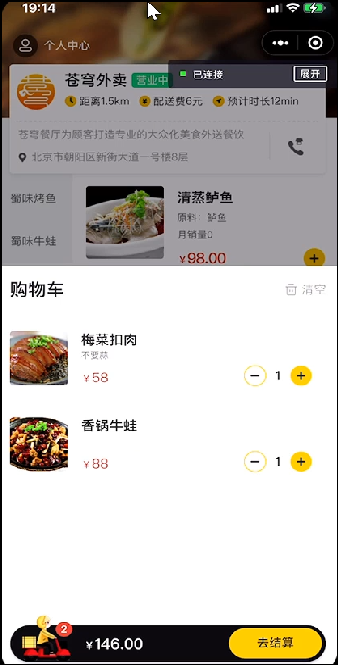    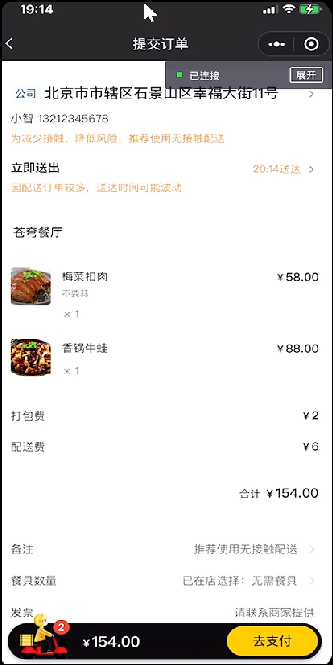     


**订单支付效果图：**

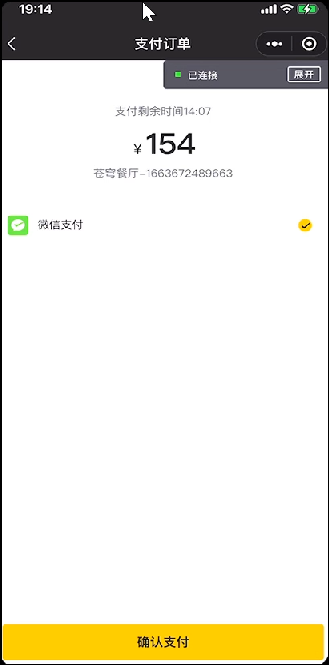    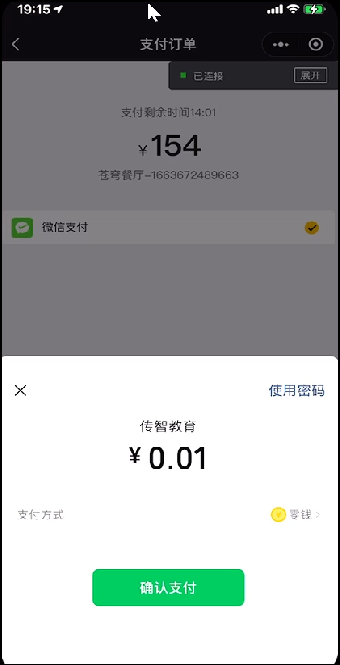    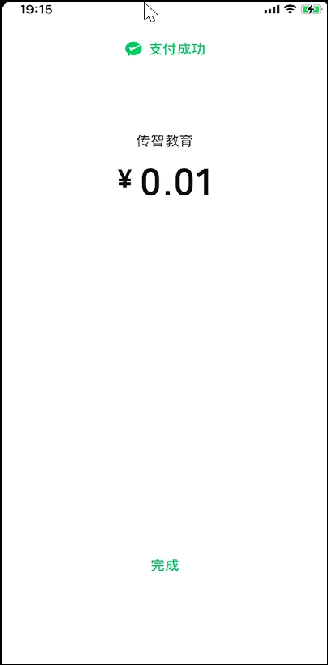


## 1. 导入地址簿功能代码

> **PPT对照：** 第4—18页。


### 1.1 需求分析和设计

> **PPT对照：** 第5—14页。

#### 1.1.1 产品原型

地址簿，指的是消费者用户的地址信息，用户登录成功后可以维护自己的地址信息。同一个用户可以有多个地址信息，但是只能有一个**默认地址**。

**效果图：**

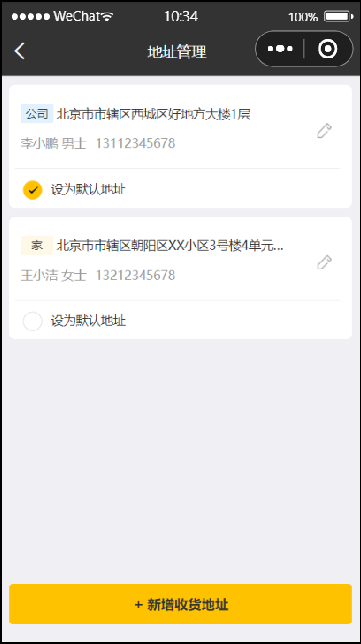      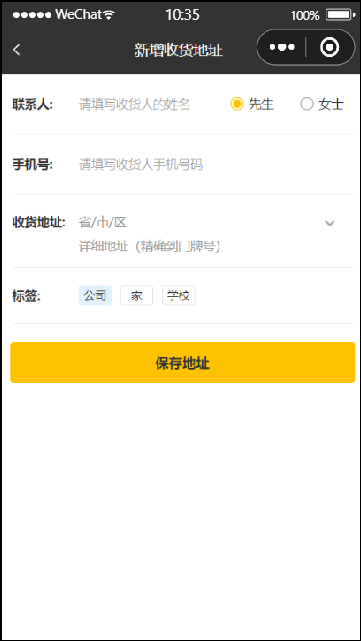       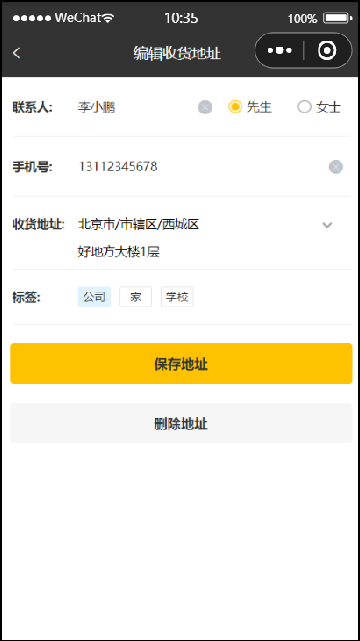 

对于地址簿管理，我们需要实现以下几个功能： 

- 查询地址列表
- 新增地址
- 修改地址
- 删除地址
- 设置默认地址
- 查询默认地址


#### 1.1.2 接口设计

根据上述原型图先**粗粒度**设计接口，共包含7个接口。

**接口设计：**

- 新增地址
- 查询登录用户所有地址
- 查询默认地址
- 根据id修改地址
- 根据id删除地址
- 根据id查询地址
- 设置默认地址

接下来**细粒度**分析每个接口，明确每个接口的请求方式、请求路径、传入参数和返回值。


**1). 新增地址**

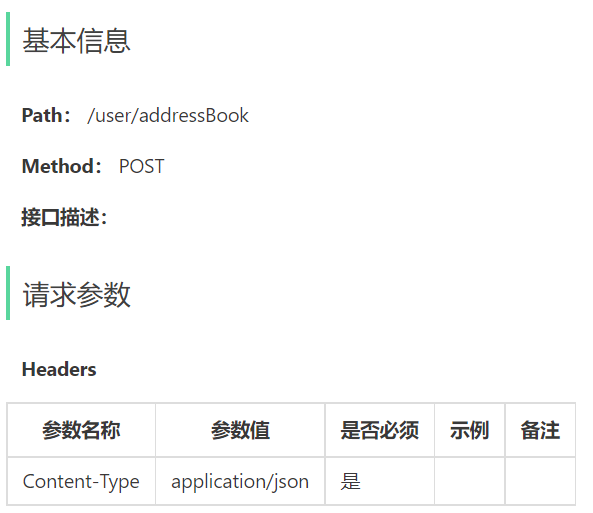 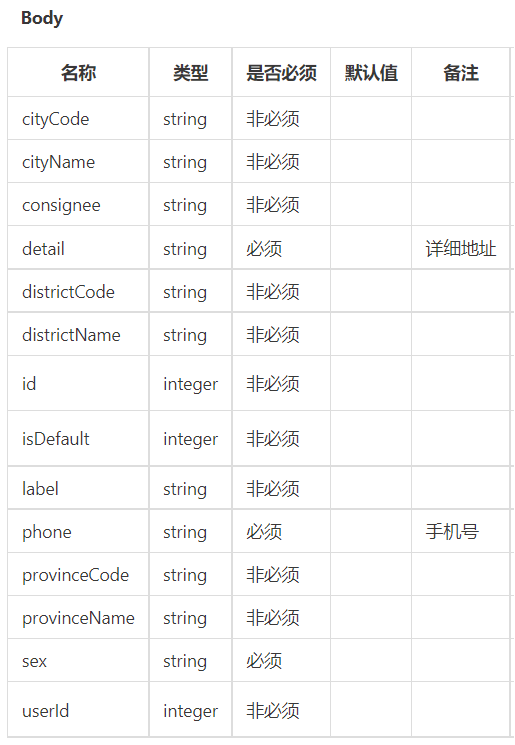 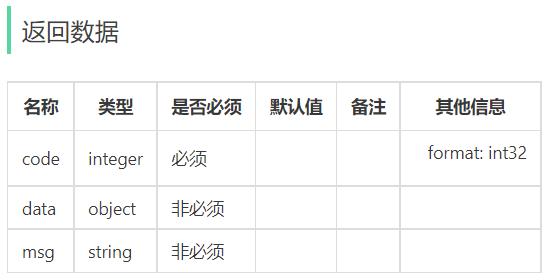 


**2). 查询登录用户所有地址**

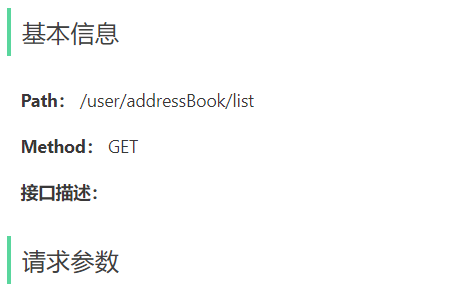 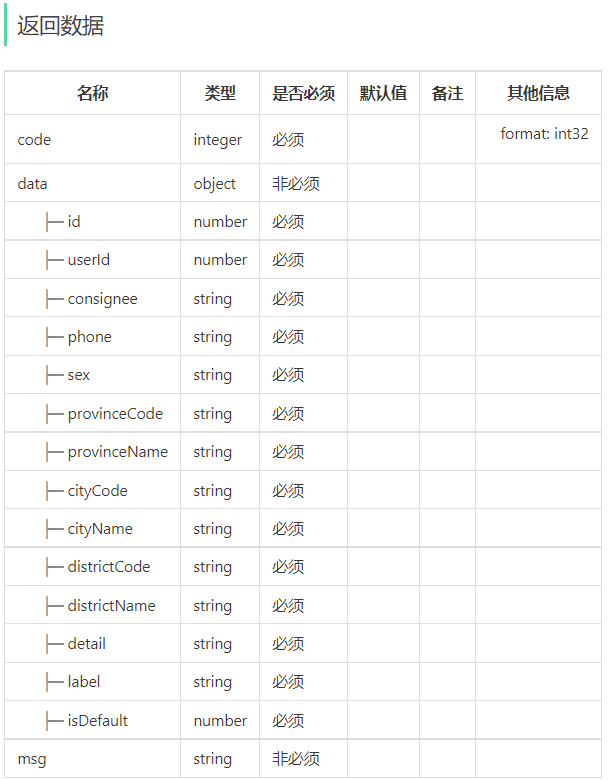 


**3). 查询默认地址**

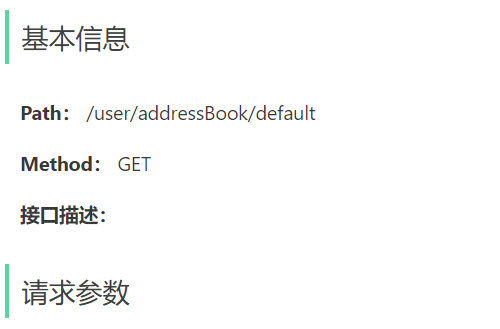 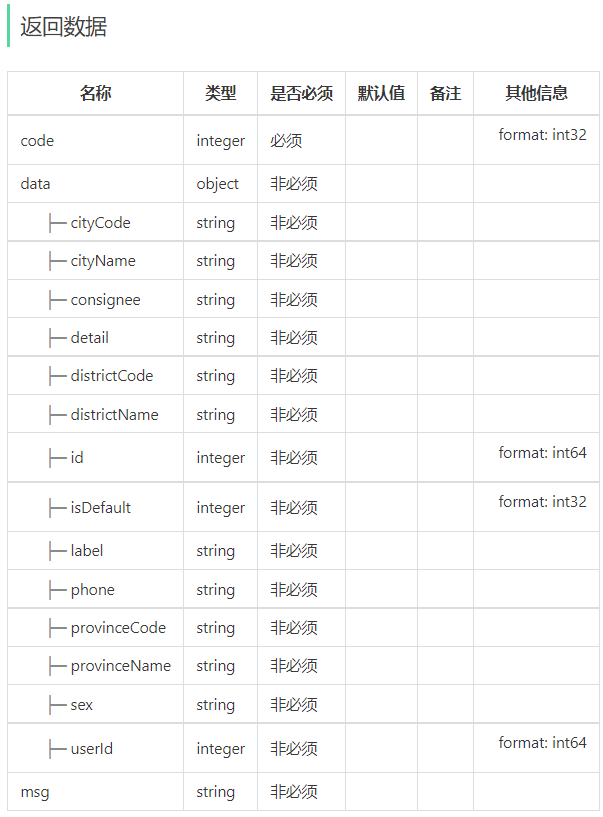 


**4). 修改地址**

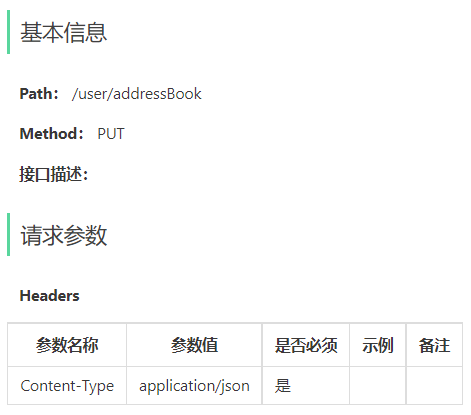 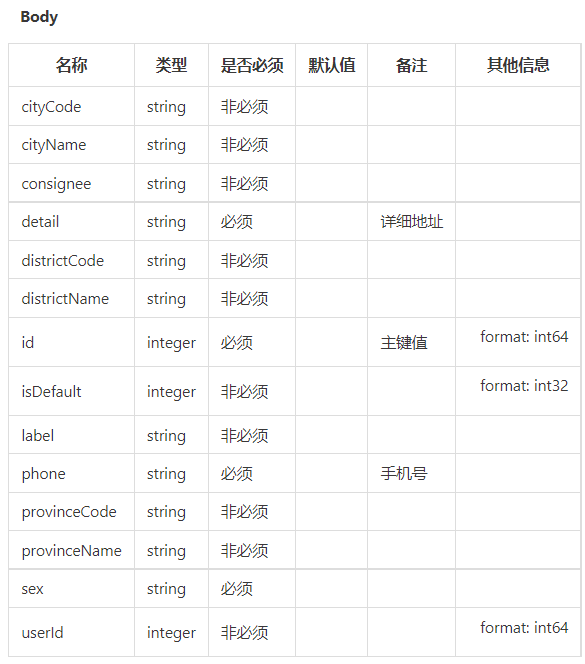 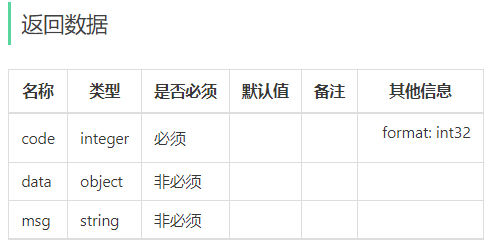 


**5). 根据id删除地址**

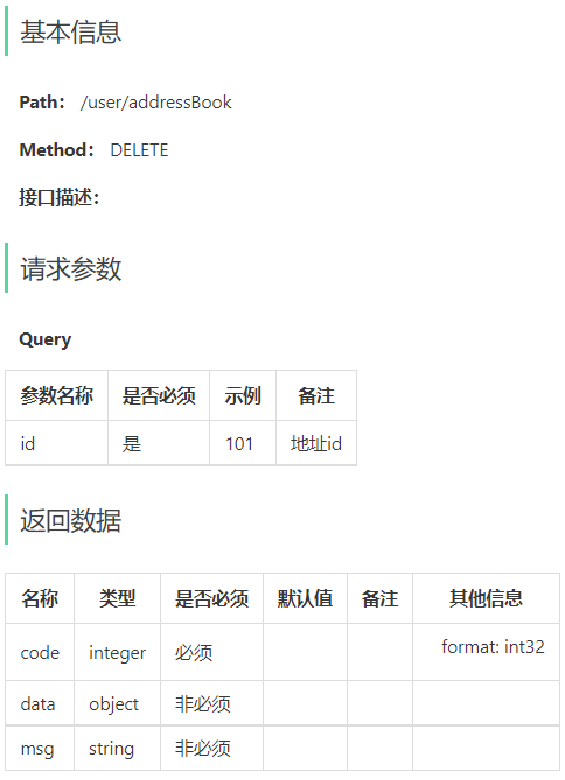 


**6). 根据id查询地址**

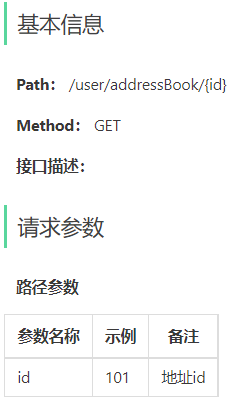 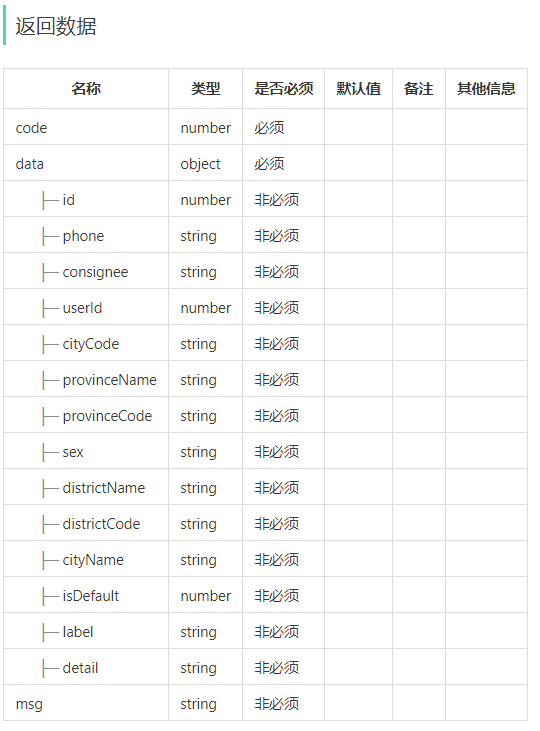 


**7). 设置默认地址**

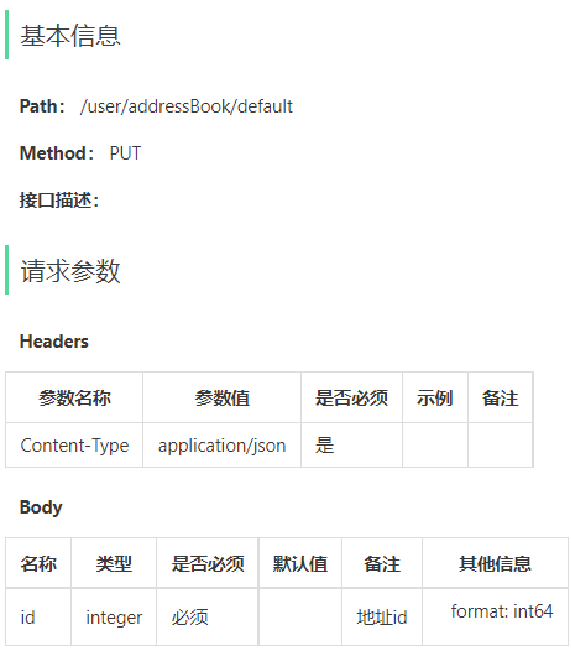 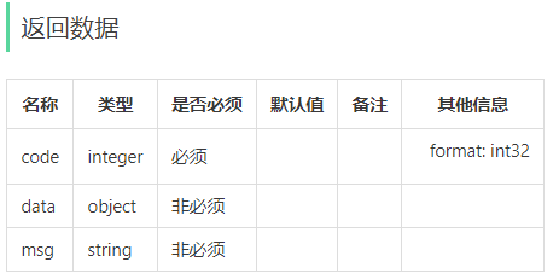 


#### 1.1.3 表设计

用户的地址信息会存储在address_book表，即地址簿表中。具体表结构如下：

| **字段名**    | **数据类型** | **说明**     | **备注**       |
| ------------- | ------------ | ------------ | -------------- |
| id            | bigint       | 主键         | 自增           |
| user_id       | bigint       | 用户id       | 逻辑外键       |
| consignee     | varchar(50)  | 收货人       |                |
| sex           | varchar(2)   | 性别         |                |
| phone         | varchar(11)  | 手机号       |                |
| province_code | varchar(12)  | 省份编码     |                |
| province_name | varchar(32)  | 省份名称     |                |
| city_code     | varchar(12)  | 城市编码     |                |
| city_name     | varchar(32)  | 城市名称     |                |
| district_code | varchar(12)  | 区县编码     |                |
| district_name | varchar(32)  | 区县名称     |                |
| detail        | varchar(200) | 详细地址信息 | 具体到门牌号   |
| label         | varchar(100) | 标签         | 公司、家、学校 |
| is_default    | tinyint(1)   | 是否默认地址 | 1是 0否        |

这里面有一个字段is_default，实际上我们在设置默认地址时，只需要更新这个字段就可以了。


### 地址所属用户与默认状态（补充）

同一用户可有多条地址，最多一条默认地址。原新增统一设置isDefault=0，不会自动让第一条地址成为默认项；删除默认地址后也没有自动挑选替代地址。是否自动设置默认要形成明确业务约定。

省市区编码、名称与detail分别表示行政区和详细门牌。订单配送需要完整可用的地址，并非只保存detail就足够。用户id来自已验证的登录态，不能由前端随意指定。

按id查询、修改、删除、设置默认都必须检查该地址属于当前用户。仅“地址列表只查自己的”不能保护其他直接按id调用的接口。


### 1.2 代码导入

> **PPT对照：** 第16页，详细Mapper/Service/Controller由讲义展开。

对于这一类的单表的增删改查，我们已经写过很多了，基本的开发思路都是一样的，那么本小节的用户地址簿管理的增删改查功能，我们就不再一一实现了，基本的代码我们都已经提供了，直接导入进来，做一个测试即可。

导入课程资料中的地址簿模块功能代码：

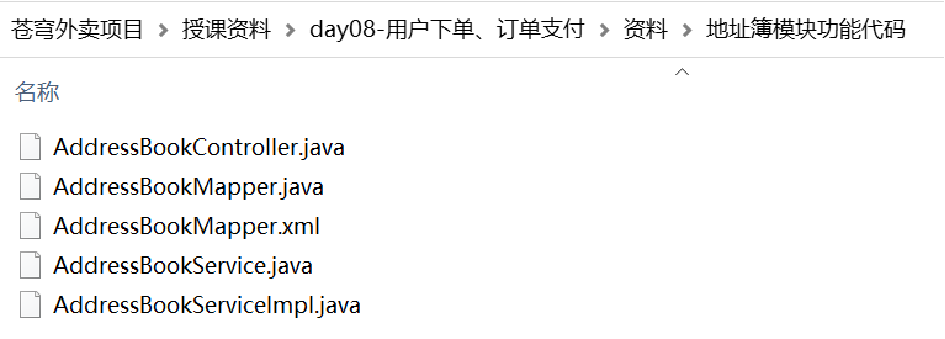 

进入到sky-server模块中

#### 1.2.1 Mapper层

**创建AddressBookMapper.java**

```java
package com.sky.mapper;

import com.sky.entity.AddressBook;
import org.apache.ibatis.annotations.*;
import java.util.List;

@Mapper
public interface AddressBookMapper {

    /**
     * 条件查询
     * @param addressBook
     * @return
     */
    List<AddressBook> list(AddressBook addressBook);

    /**
     * 新增
     * @param addressBook
     */
    @Insert("insert into address_book" +
            "        (user_id, consignee, phone, sex, province_code, province_name, city_code, city_name, district_code," +
            "         district_name, detail, label, is_default)" +
            "        values (#{userId}, #{consignee}, #{phone}, #{sex}, #{provinceCode}, #{provinceName}, #{cityCode}, #{cityName}," +
            "                #{districtCode}, #{districtName}, #{detail}, #{label}, #{isDefault})")
    void insert(AddressBook addressBook);

    /**
     * 根据id查询
     * @param id
     * @return
     */
    @Select("select * from address_book where id = #{id}")
    AddressBook getById(Long id);

    /**
     * 根据id修改
     * @param addressBook
     */
    void update(AddressBook addressBook);

    /**
     * 根据 用户id修改 是否默认地址
     * @param addressBook
     */
    @Update("update address_book set is_default = #{isDefault} where user_id = #{userId}")
    void updateIsDefaultByUserId(AddressBook addressBook);

    /**
     * 根据id删除地址
     * @param id
     */
    @Delete("delete from address_book where id = #{id}")
    void deleteById(Long id);

}
```

**创建AddressBookMapper.xml**

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN" "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.AddressBookMapper">

    <select id="list" parameterType="AddressBook" resultType="AddressBook">
        select * from address_book
        <where>
            <if test="userId != null">
                and user_id = #{userId}
            </if>
            <if test="phone != null">
                and phone = #{phone}
            </if>
            <if test="isDefault != null">
                and is_default = #{isDefault}
            </if>
        </where>
    </select>

    <update id="update" parameterType="addressBook">
        update address_book
        <set>
            <if test="consignee != null">
                consignee = #{consignee},
            </if>
            <if test="sex != null">
                sex = #{sex},
            </if>
            <if test="phone != null">
                phone = #{phone},
            </if>
            <if test="detail != null">
                detail = #{detail},
            </if>
            <if test="label != null">
                label = #{label},
            </if>
            <if test="isDefault != null">
                is_default = #{isDefault},
            </if>
        </set>
        where id = #{id}
    </update>

</mapper>
```


#### 1.2.2 Service层

**创建AddressBookService.java**

```java
package com.sky.service;

import com.sky.entity.AddressBook;
import java.util.List;

public interface AddressBookService {

    List<AddressBook> list(AddressBook addressBook);

    void save(AddressBook addressBook);

    AddressBook getById(Long id);

    void update(AddressBook addressBook);

    void setDefault(AddressBook addressBook);

    void deleteById(Long id);

}
```

**创建AddressBookServiceImpl.java**

```java
package com.sky.service.impl;

import com.sky.context.BaseContext;
import com.sky.entity.AddressBook;
import com.sky.mapper.AddressBookMapper;
import com.sky.service.AddressBookService;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Service;
import org.springframework.transaction.annotation.Transactional;
import java.util.List;

@Service
@Slf4j
public class AddressBookServiceImpl implements AddressBookService {
    @Autowired
    private AddressBookMapper addressBookMapper;

    /**
     * 条件查询
     *
     * @param addressBook
     * @return
     */
    public List<AddressBook> list(AddressBook addressBook) {
        return addressBookMapper.list(addressBook);
    }

    /**
     * 新增地址
     *
     * @param addressBook
     */
    public void save(AddressBook addressBook) {
        addressBook.setUserId(BaseContext.getCurrentId());
        addressBook.setIsDefault(0);
        addressBookMapper.insert(addressBook);
    }

    /**
     * 根据id查询
     *
     * @param id
     * @return
     */
    public AddressBook getById(Long id) {
        AddressBook addressBook = addressBookMapper.getById(id);
        return addressBook;
    }

    /**
     * 根据id修改地址
     *
     * @param addressBook
     */
    public void update(AddressBook addressBook) {
        addressBookMapper.update(addressBook);
    }

    /**
     * 设置默认地址
     *
     * @param addressBook
     */
    @Transactional
    public void setDefault(AddressBook addressBook) {
        //1、将当前用户的所有地址修改为非默认地址 update address_book set is_default = ? where user_id = ?
        addressBook.setIsDefault(0);
        addressBook.setUserId(BaseContext.getCurrentId());
        addressBookMapper.updateIsDefaultByUserId(addressBook);

        //2、将当前地址改为默认地址 update address_book set is_default = ? where id = ?
        addressBook.setIsDefault(1);
        addressBookMapper.update(addressBook);
    }

    /**
     * 根据id删除地址
     *
     * @param id
     */
    public void deleteById(Long id) {
        addressBookMapper.deleteById(id);
    }

}
```


#### 1.2.3 Controller层

```java
package com.sky.controller.user;

import com.sky.context.BaseContext;
import com.sky.entity.AddressBook;
import com.sky.result.Result;
import com.sky.service.AddressBookService;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.*;
import java.util.List;

@RestController
@RequestMapping("/user/addressBook")
@Api(tags = "C端地址簿接口")
public class AddressBookController {

    @Autowired
    private AddressBookService addressBookService;

    /**
     * 查询当前登录用户的所有地址信息
     *
     * @return
     */
    @GetMapping("/list")
    @ApiOperation("查询当前登录用户的所有地址信息")
    public Result<List<AddressBook>> list() {
        AddressBook addressBook = new AddressBook();
        addressBook.setUserId(BaseContext.getCurrentId());
        List<AddressBook> list = addressBookService.list(addressBook);
        return Result.success(list);
    }

    /**
     * 新增地址
     *
     * @param addressBook
     * @return
     */
    @PostMapping
    @ApiOperation("新增地址")
    public Result save(@RequestBody AddressBook addressBook) {
        addressBookService.save(addressBook);
        return Result.success();
    }

    @GetMapping("/{id}")
    @ApiOperation("根据id查询地址")
    public Result<AddressBook> getById(@PathVariable Long id) {
        AddressBook addressBook = addressBookService.getById(id);
        return Result.success(addressBook);
    }

    /**
     * 根据id修改地址
     *
     * @param addressBook
     * @return
     */
    @PutMapping
    @ApiOperation("根据id修改地址")
    public Result update(@RequestBody AddressBook addressBook) {
        addressBookService.update(addressBook);
        return Result.success();
    }

    /**
     * 设置默认地址
     *
     * @param addressBook
     * @return
     */
    @PutMapping("/default")
    @ApiOperation("设置默认地址")
    public Result setDefault(@RequestBody AddressBook addressBook) {
        addressBookService.setDefault(addressBook);
        return Result.success();
    }

    /**
     * 根据id删除地址
     *
     * @param id
     * @return
     */
    @DeleteMapping
    @ApiOperation("根据id删除地址")
    public Result deleteById(Long id) {
        addressBookService.deleteById(id);
        return Result.success();
    }

    /**
     * 查询默认地址
     */
    @GetMapping("default")
    @ApiOperation("查询默认地址")
    public Result<AddressBook> getDefault() {
        //SQL:select * from address_book where user_id = ? and is_default = 1
        AddressBook addressBook = new AddressBook();
        addressBook.setIsDefault(1);
        addressBook.setUserId(BaseContext.getCurrentId());
        List<AddressBook> list = addressBookService.list(addressBook);

        if (list != null && list.size() == 1) {
            return Result.success(list.get(0));
        }

        return Result.error("没有查询到默认地址");
    }

}
```


### 地址归属、更新字段与默认事务（补充与勘误）

#### 1. 原按id操作未限定当前用户

原getById和deleteById仅按id，原update的where也只有id；设置默认先清除自己的默认项，再按客户端id更新，若没有归属检查会操作错误用户的地址。

先在AddressBookServiceImpl增加当前用户检查，并让列表查询强制使用这个用户。按id操作可增加专门Mapper方法：

```java
@Select("select * from address_book where id = #{id} and user_id = #{userId}")
AddressBook getByIdAndUserId(
        @org.apache.ibatis.annotations.Param("id") Long id,
        @org.apache.ibatis.annotations.Param("userId") Long userId);

@Delete("delete from address_book where id = #{id} and user_id = #{userId}")
int deleteByIdAndUserId(
        @org.apache.ibatis.annotations.Param("id") Long id,
        @org.apache.ibatis.annotations.Param("userId") Long userId);
```

Service不接收客户端userId作为授权依据，使用BaseContext读取后传给Mapper；查询不到时按不存在或无权访问统一报业务错误。列表也先拒绝缺失身份，避免原动态SQL省略user_id条件后查询全部记录。

#### 2. 原update漏掉省市区字段

原XML只更新consignee、sex、phone、detail、label、isDefault。用户修改省市区时，即使请求带了这些字段，原SQL仍不会保存。

在现有update的set节点内按业务补齐provinceCode/provinceName、cityCode/cityName、districtCode/districtName，并把where改成必须包含用户：

```xml
<!-- 放入原set节点，其他允许修改的字段沿用原条件。 -->
<if test="provinceCode != null">province_code = #{provinceCode},</if>
<if test="provinceName != null">province_name = #{provinceName},</if>
<if test="cityCode != null">city_code = #{cityCode},</if>
<if test="cityName != null">city_name = #{cityName},</if>
<if test="districtCode != null">district_code = #{districtCode},</if>
<if test="districtName != null">district_name = #{districtName},</if>

<!-- 原update语句尾部的替换条件，须在set节点结束之后。 -->
where id = #{id} and user_id = #{userId}
```

Service设置userId为当前用户并检查目标存在，Mapper最好返回影响行数。不要允许普通地址编辑直接写isDefault=1绕过默认项流程；用专用DTO白名单接收地址字段，或在普通update中清除客户端的默认字段。

新增同样忽略客户端id、userId和isDefault：id由数据库生成，userId取当前用户，默认按原规则0。校验收货人、手机号和地址字段长度；JSON格式正确不等于地址可配送。

#### 3. 设置默认仍需事务，但要先验证目标

原setDefault已有@Transactional，保持这一点。先验证目标属于当前用户，再把自己的默认项清零，再仅更新目标的默认标志，不复用客户端完整地址对象改其他字段。

可在Mapper加专用更新，返回影响行数：

```java
@Update("update address_book set is_default = 1 " +
        "where id = #{id} and user_id = #{userId}")
int markDefault(
        @org.apache.ibatis.annotations.Param("id") Long id,
        @org.apache.ibatis.annotations.Param("userId") Long userId);
```

Service补充示例使用已增加的getByIdAndUserId与markDefault，沿用原Mapper的updateIsDefaultByUserId：

```java
private Long requireCurrentUserId() {
    Long userId = BaseContext.getCurrentId();
    if (userId == null || userId <= 0) {
        throw new IllegalStateException("缺少当前登录用户");
    }
    return userId;
}

@Override
@Transactional(rollbackFor = Exception.class)
public void setDefault(AddressBook input) {
    Long userId = requireCurrentUserId();
    if (input == null || input.getId() == null || input.getId() <= 0) {
        throw new IllegalArgumentException("地址id不合法");
    }
    AddressBook target = addressBookMapper.getByIdAndUserId(input.getId(), userId);
    if (target == null) {
        throw new IllegalArgumentException("地址不存在或无权访问");
    }
    AddressBook reset = new AddressBook();
    reset.setUserId(userId);
    reset.setIsDefault(0);
    addressBookMapper.updateIsDefaultByUserId(reset);
    if (addressBookMapper.markDefault(target.getId(), userId) != 1) {
        throw new IllegalStateException("默认地址更新失败");
    }
}
```

异常需接入工程已有统一处理器。该示例修正归属与失败回滚；并发请求同时设置不同默认地址，仍需明确按用户串行的锁定或数据库约束方案，不能只看到@Transactional就宣称默认项严格唯一。

查询默认地址时，0条与大于1条是不同情形：0条可提示先设置，多个默认项应识别数据异常。若删除默认地址，应按约定保留“无默认项”或选择替代，不悄悄假设原代码已自动处理。

#### 导入位置

初始工程已有AddressBook实体时复用，不重建另一套字段；XML别名未配置时用完整类名。getDefault的GetMapping("default")通常可正常拼接路径，为阅读统一可写"/default"，无需把缺少开头斜杠误判成必然404。


### 1.3 功能测试

> **PPT对照：** 第18页。

可以通过如下方式进行测试：

- 查看控制台sql和数据库中的数据变化
- Swagger接口文档测试
- 前后端联调

我们直接使用**前后端联调**测试：

启动后台服务，编译小程序

登录进入首页-->进入个人中心-->进入地址管理

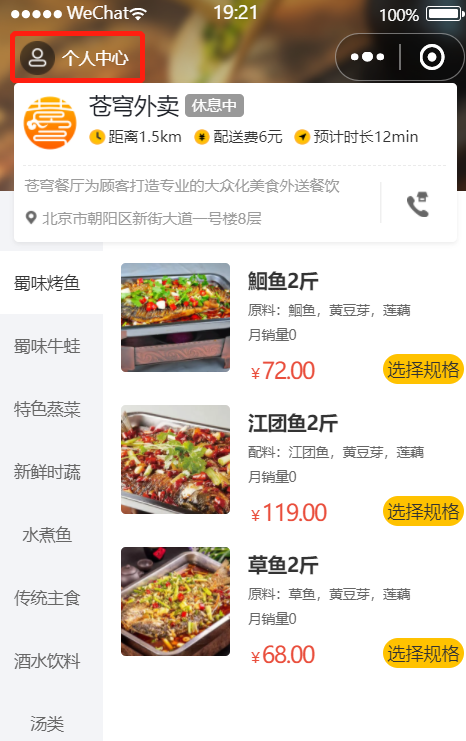 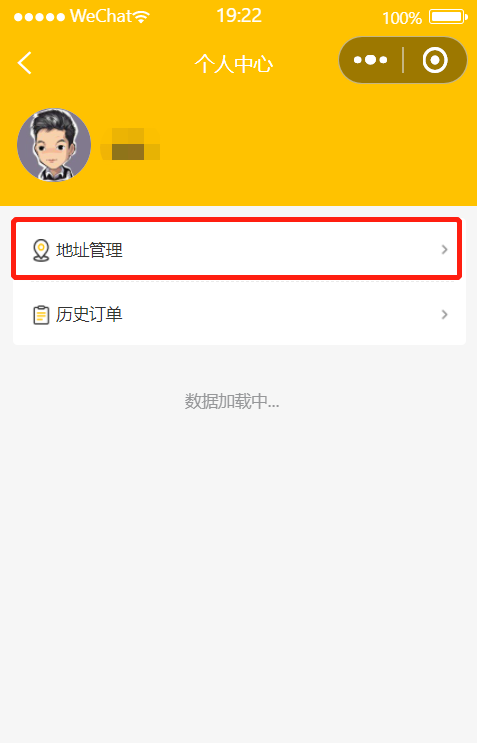 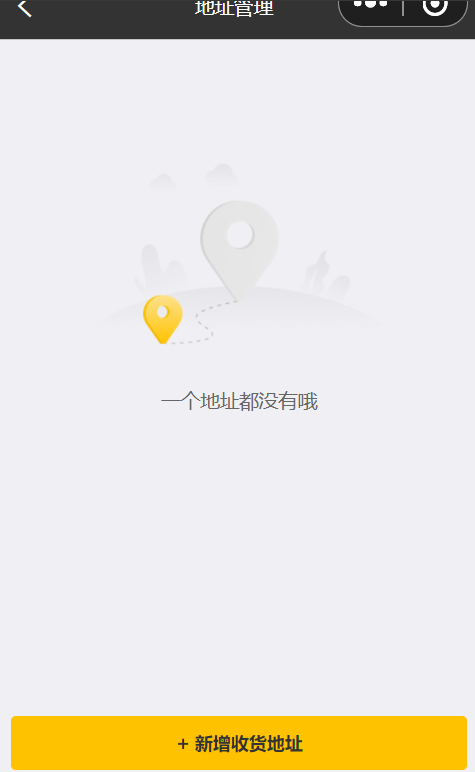 


**1). 新增收货地址**

**添加两条收货地址：**

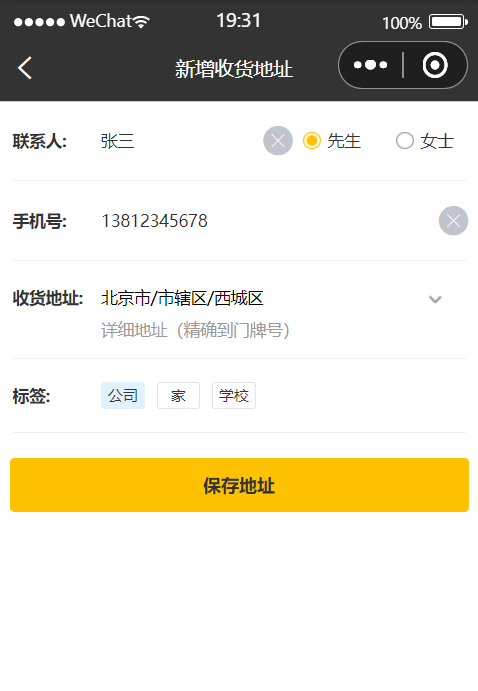 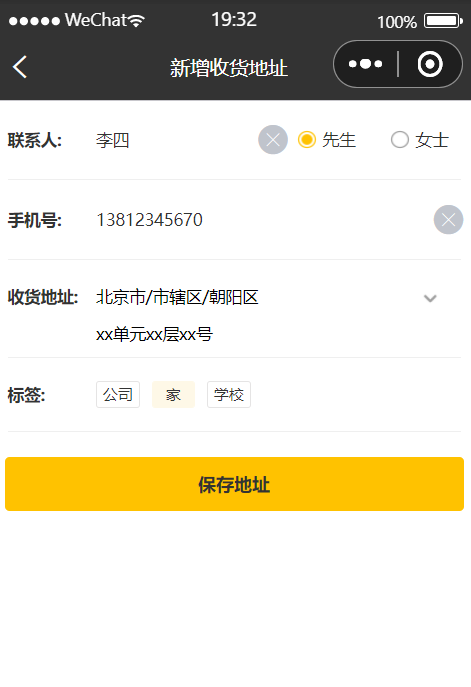 


**查看收货地址：**

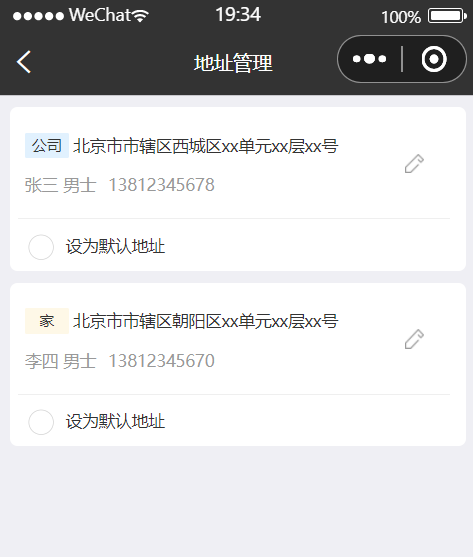 


**查看数据库：**

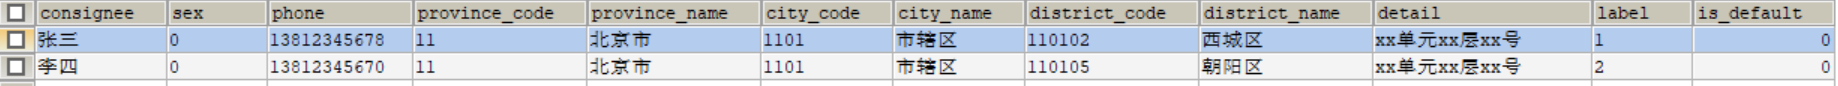 


**2). 设置默认收货地址**

**设置默认地址：**

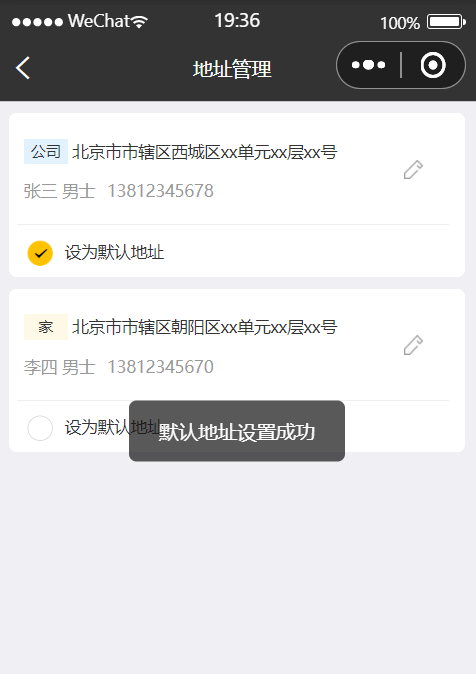 

**查看数据库：**

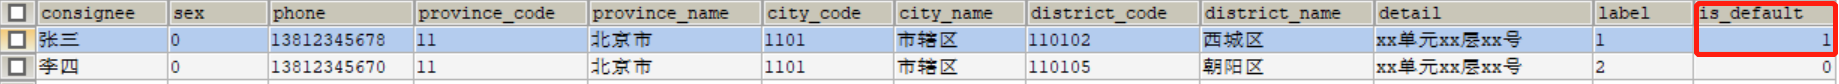 


**3). 删除收货地址**

**进行编辑：**

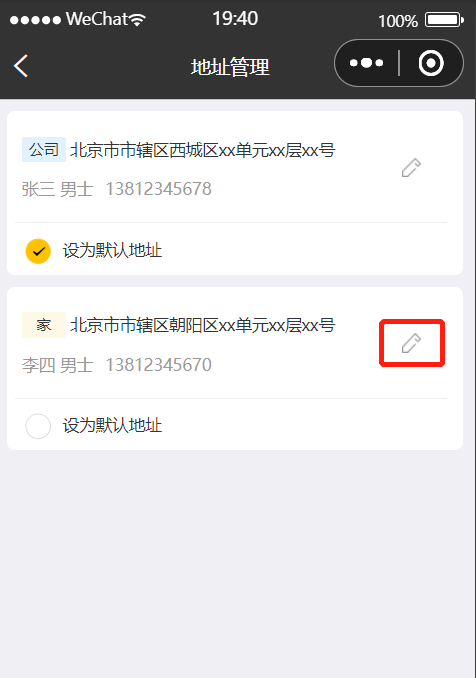 

**删除地址：**

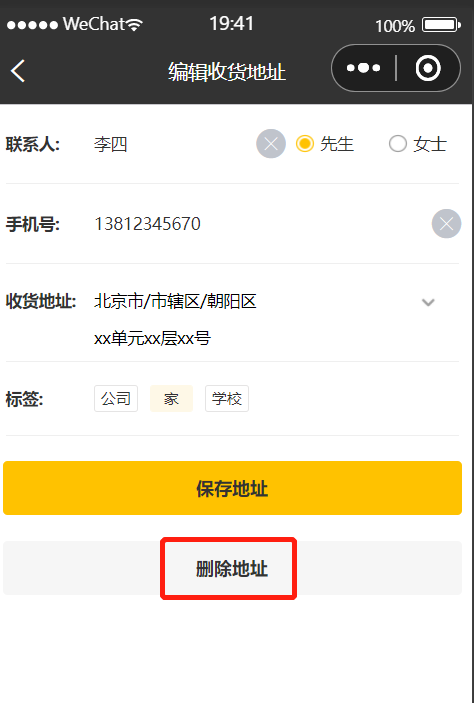 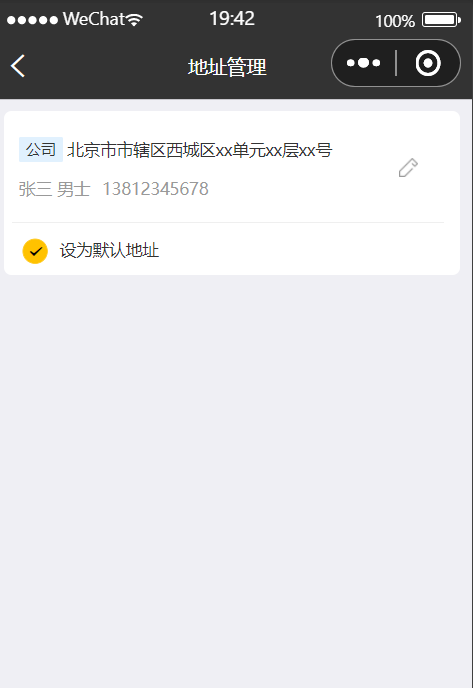

**查看数据库：**

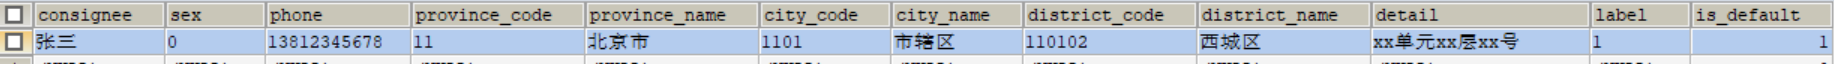


### 地址簿验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 新增两条地址 | userId取当前用户，默认都为0，字段保存完整 |
| 查询列表、按id回显 | 只访问当前用户自己的地址 |
| 修改省市区与门牌 | 相应字段都保存，不只改变detail |
| 切换默认A→B | 当前用户只剩B默认，其他用户不变 |
| 默认操作中途失败 | 前一次默认状态回滚保留 |
| 查询/编辑/删除/设默认使用另一用户id | 拒绝，原数据不变 |
| 无登录身份 | 拒绝，不把用户条件省略成全表查询 |
| 删除默认项 | 按约定处理无默认或替代，页面能提示 |

用测试地址和手机号跟练；显示截图时不要使用真实个人地址。日志与示例资料仅用于排查字段保存和用户范围，不需要打印整条地址到普通日志。


### 1.4 代码提交

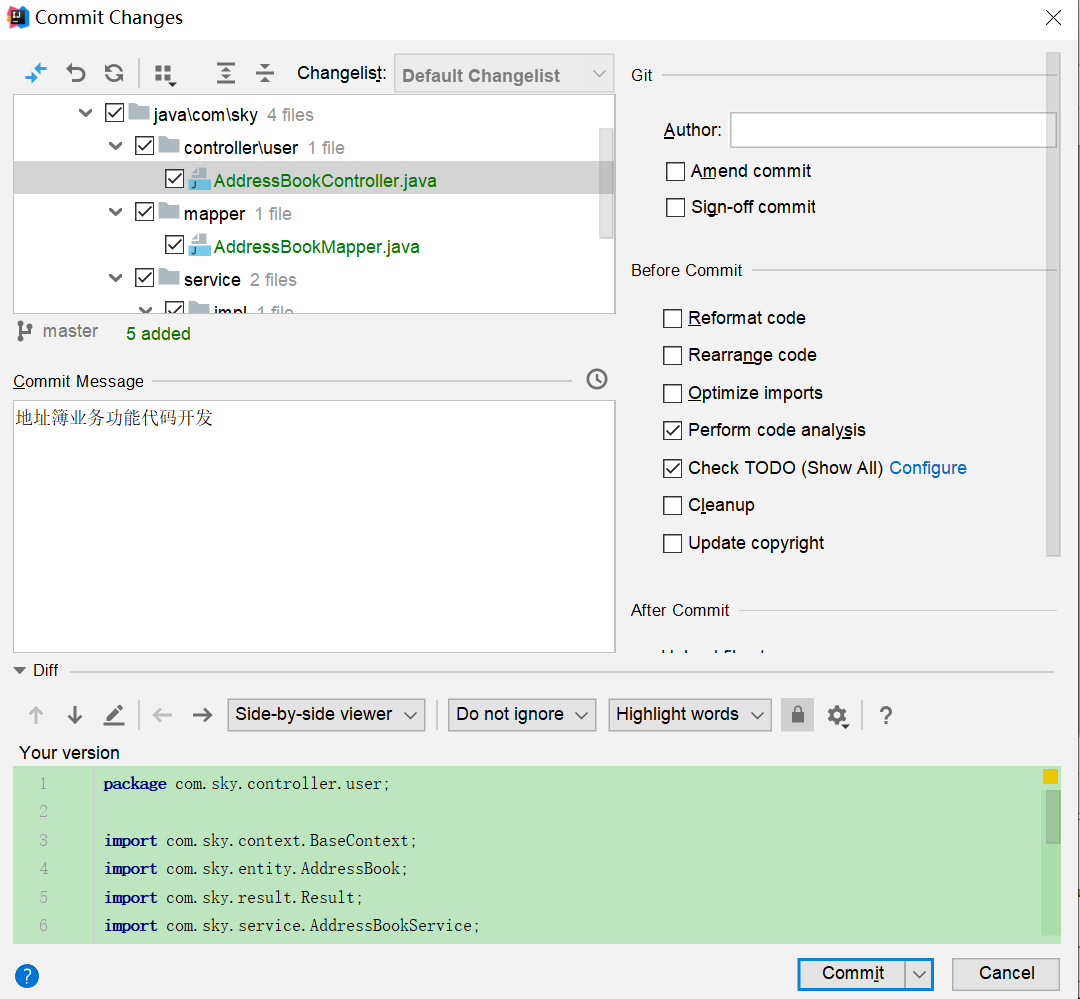 

后续步骤和其它功能代码提交一致，不再赘述。


## 2. 用户下单

> **PPT对照：** 第20—41页。


### 2.1 需求分析和设计

> **PPT对照：** 第21—28页。

#### 2.1.1 产品原型

**用户下单业务说明：**
在电商系统中，用户是通过下单的方式通知商家，用户已经购买了商品，需要商家进行备货和发货。
用户下单后会产生订单相关数据，订单数据需要能够体现如下信息：

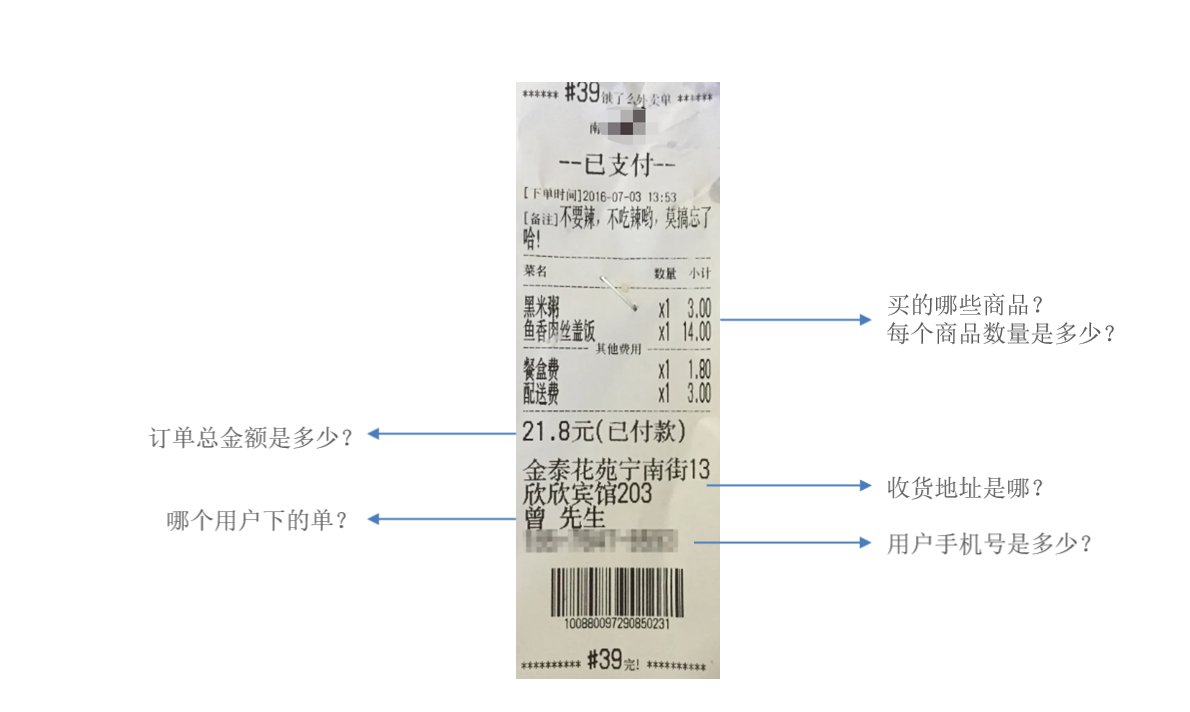 

用户将菜品或者套餐加入购物车后，可以点击购物车中的 "去结算" 按钮，页面跳转到订单确认页面，点击 "去支付" 按钮则完成下单操作。

**用户点餐业务流程(效果图)：**

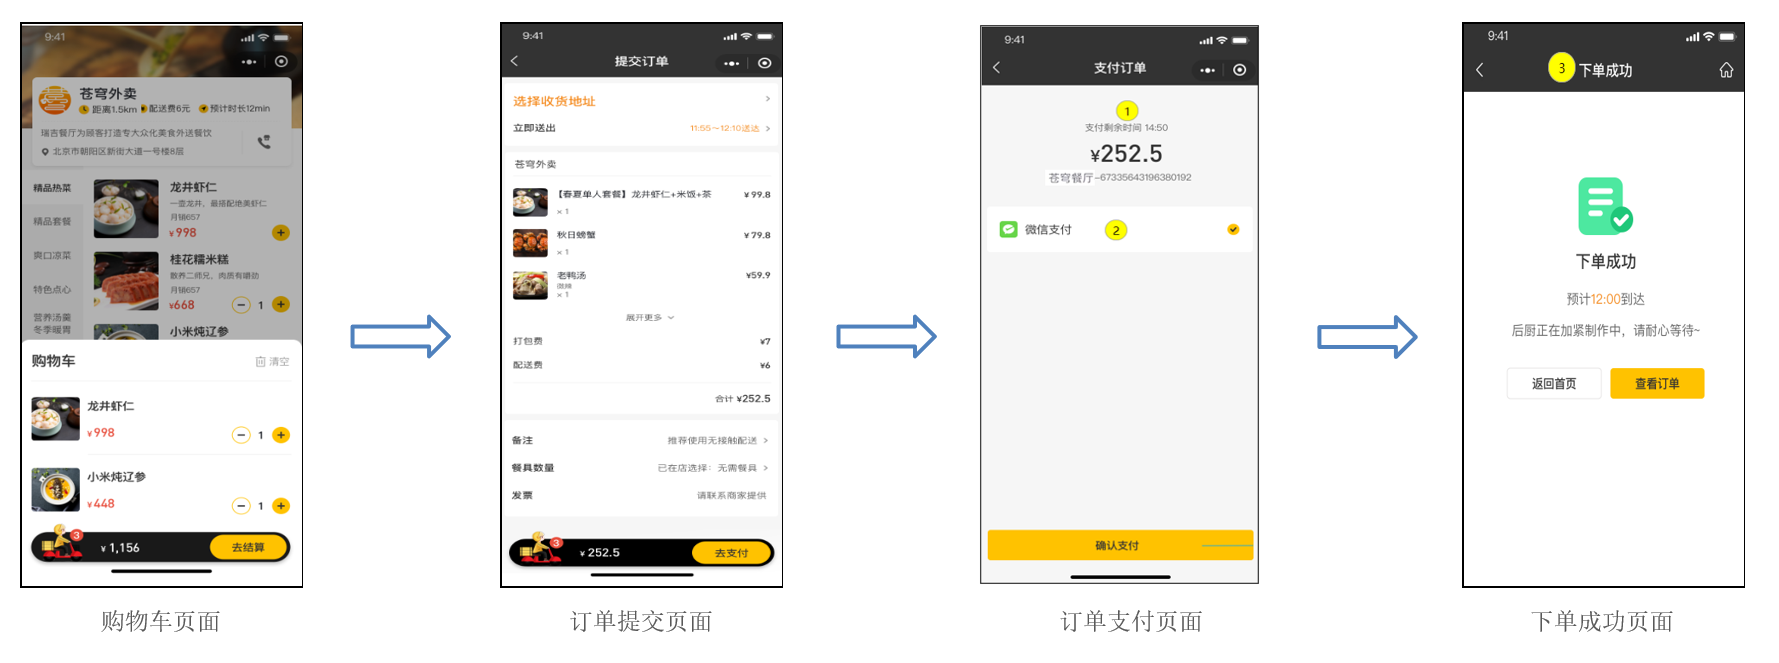 


#### 2.1.2 接口设计

**接口分析：**

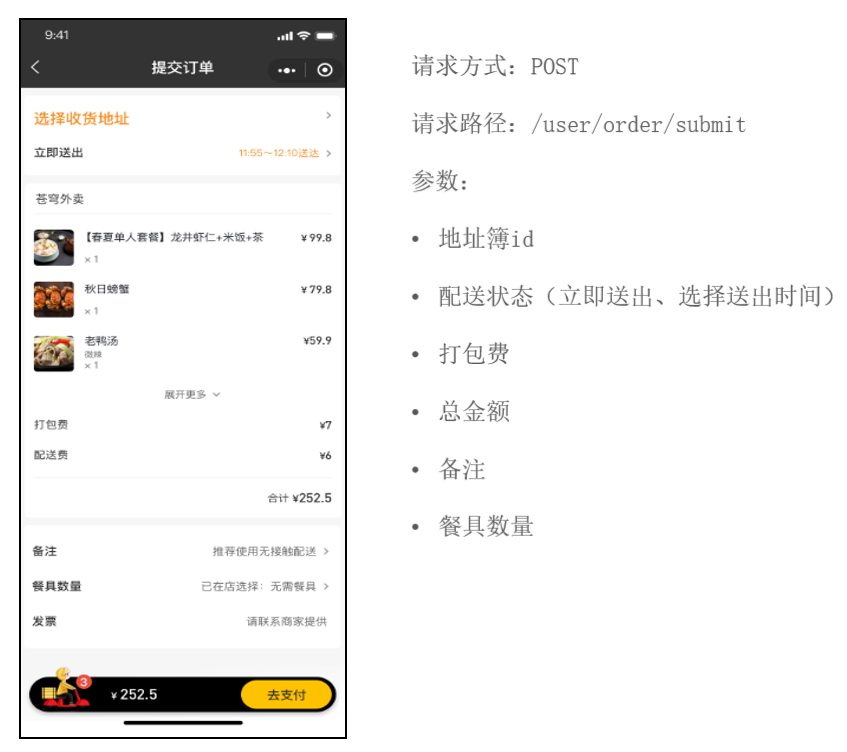 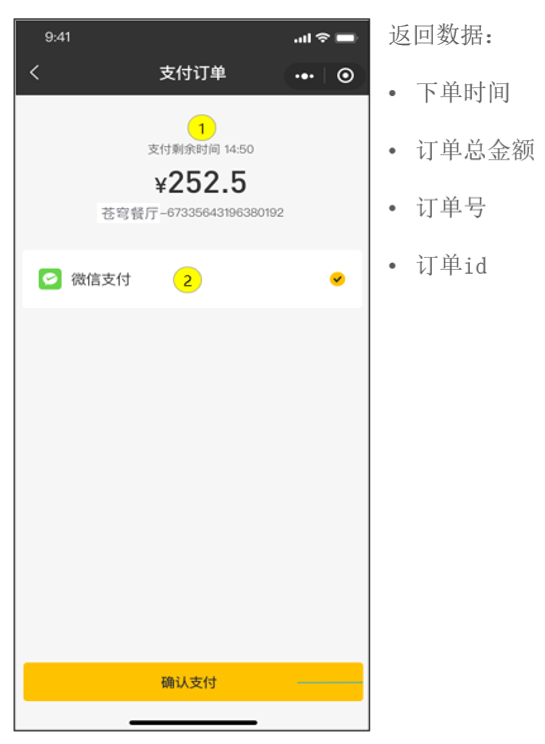 


**接口设计：**

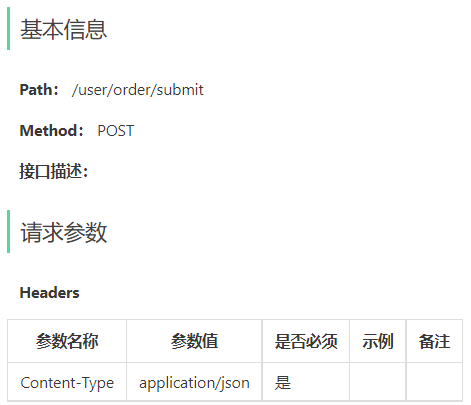 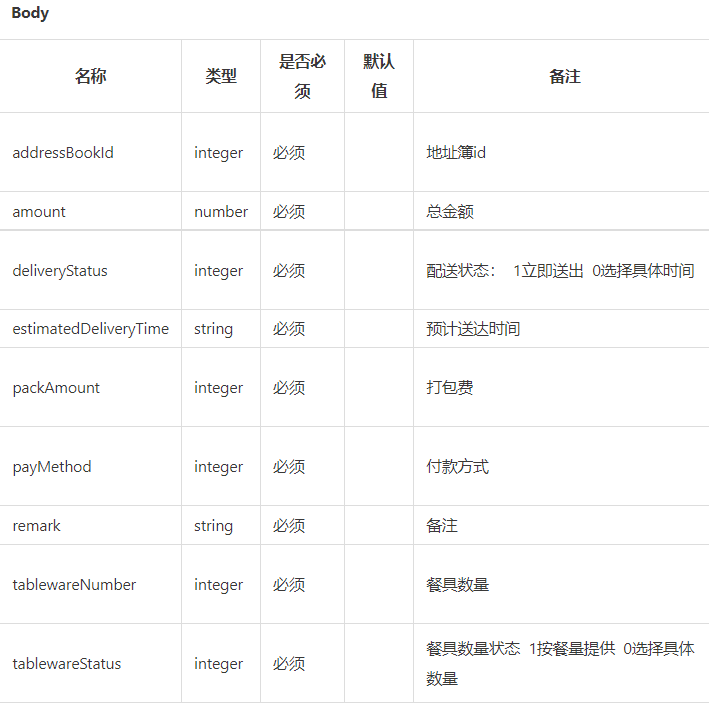 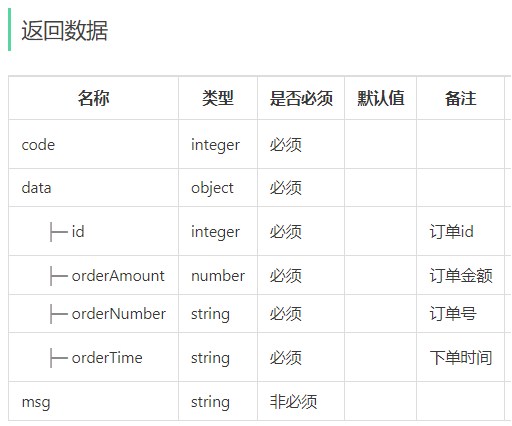 


#### 2.1.3 表设计

用户下单业务对应的数据表为orders表和order_detail表(一对多关系,一个订单关联多个订单明细)：

| 表名         | 含义       | 说明                                                         |
| ------------ | ---------- | ------------------------------------------------------------ |
| orders       | 订单表     | 主要存储订单的基本信息(如: 订单号、状态、金额、支付方式、下单用户、收件地址等) |
| order_detail | 订单明细表 | 主要存储订单详情信息(如: 该订单关联的套餐及菜品的信息)       |

具体的表结构如下: 

**1). orders订单表**

| **字段名**              | **数据类型**  | **说明**     | **备注**                                        |
| ----------------------- | ------------- | ------------ | ----------------------------------------------- |
| id                      | bigint        | 主键         | 自增                                            |
| number                  | varchar(50)   | 订单号       |                                                 |
| status                  | int           | 订单状态     | 1待付款 2待接单 3已接单 4派送中 5已完成 6已取消 |
| user_id                 | bigint        | 用户id       | 逻辑外键                                        |
| address_book_id         | bigint        | 地址id       | 逻辑外键                                        |
| order_time              | datetime      | 下单时间     |                                                 |
| checkout_time           | datetime      | 付款时间     |                                                 |
| pay_method              | int           | 支付方式     | 1微信支付 2支付宝支付                           |
| pay_status              | tinyint       | 支付状态     | 0未支付 1已支付 2退款                           |
| amount                  | decimal(10,2) | 订单金额     |                                                 |
| remark                  | varchar(100)  | 备注信息     |                                                 |
| phone                   | varchar(11)   | 手机号       | 冗余字段                                        |
| address                 | varchar(255)  | 详细地址信息 | 冗余字段                                        |
| consignee               | varchar(32)   | 收货人       | 冗余字段                                        |
| cancel_reason           | varchar(255)  | 订单取消原因 |                                                 |
| rejection_reason        | varchar(255)  | 拒单原因     |                                                 |
| cancel_time             | datetime      | 订单取消时间 |                                                 |
| estimated_delivery_time | datetime      | 预计送达时间 |                                                 |
| delivery_status         | tinyint       | 配送状态     | 1立即送出 0选择具体时间                         |
| delivery_time           | datetime      | 送达时间     |                                                 |
| pack_amount             | int           | 打包费       |                                                 |
| tableware_number        | int           | 餐具数量     |                                                 |
| tableware_status        | tinyint       | 餐具数量状态 | 1按餐量提供 0选择具体数量                       |


**2). order_detail订单明细表**

| **字段名**  | **数据类型**  | **说明**     | **备注** |
| ----------- | ------------- | ------------ | -------- |
| id          | bigint        | 主键         | 自增     |
| name        | varchar(32)   | 商品名称     | 冗余字段 |
| image       | varchar(255)  | 商品图片路径 | 冗余字段 |
| order_id    | bigint        | 订单id       | 逻辑外键 |
| dish_id     | bigint        | 菜品id       | 逻辑外键 |
| setmeal_id  | bigint        | 套餐id       | 逻辑外键 |
| dish_flavor | varchar(50)   | 菜品口味     |          |
| number      | int           | 商品数量     |          |
| amount      | decimal(10,2) | 商品单价     |          |

**说明：**用户提交订单时，需要往订单表orders中插入一条记录，并且需要往order_detail中插入一条或多条记录。


### 下单不是已经付款（补充）

点击“去支付”通常先提交本地订单，再发起支付。此时订单应为待付款、未支付；用户取消微信支付窗口，也不应因此把本地订单当作已支付或直接删除。

orders.id是数据库主键，orders.number是供支付平台及业务使用的订单号，order_detail.order_id关联的是id而不是number。订单号须唯一，重复提交同一次结算也需要幂等规则；这是两个不同要求。

下单需要确认当前用户、自己的有效地址、非空购物车、商品可售和规格合法、数量、配送与餐具参数、服务端金额。原注释提到“超出配送范围”，实际代码没有配送范围检查，不要把注释当成实现完成。

shopping_cart.amount与order_detail.amount都是单价，orders.amount才是总额。商品行金额是单价×数量，再按实际业务加打包费、配送费并应用优惠；原课程不提供完整计费政策，不能凭空硬编码一套费用。


### 2.2 代码开发

> **PPT对照：** 第30—39页。

#### 2.2.1 DTO设计

**根据用户下单接口的参数设计DTO：**

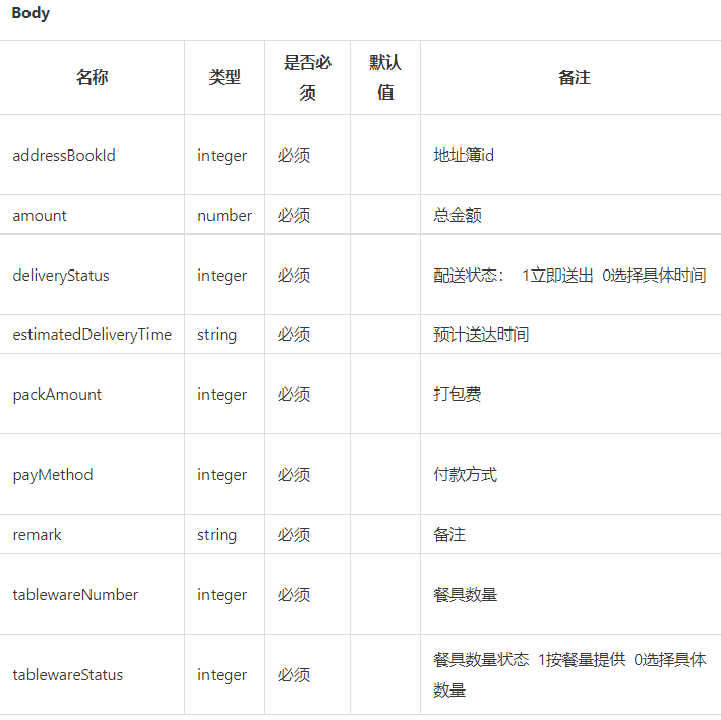 

在sky-pojo模块，OrdersSubmitDTO.java已定义

```java
package com.sky.dto;

import com.fasterxml.jackson.annotation.JsonFormat;
import lombok.Data;
import java.io.Serializable;
import java.math.BigDecimal;
import java.time.LocalDateTime;

@Data
public class OrdersSubmitDTO implements Serializable {
    //地址簿id
    private Long addressBookId;
    //付款方式
    private int payMethod;
    //备注
    private String remark;
    //预计送达时间
    @JsonFormat(shape = JsonFormat.Shape.STRING, pattern = "yyyy-MM-dd HH:mm:ss")
    private LocalDateTime estimatedDeliveryTime;
    //配送状态  1立即送出  0选择具体时间
    private Integer deliveryStatus;
    //餐具数量
    private Integer tablewareNumber;
    //餐具数量状态  1按餐量提供  0选择具体数量
    private Integer tablewareStatus;
    //打包费
    private Integer packAmount;
    //总金额
    private BigDecimal amount;
}
```


#### 2.2.2 VO设计

**根据用户下单接口的返回结果设计VO：**

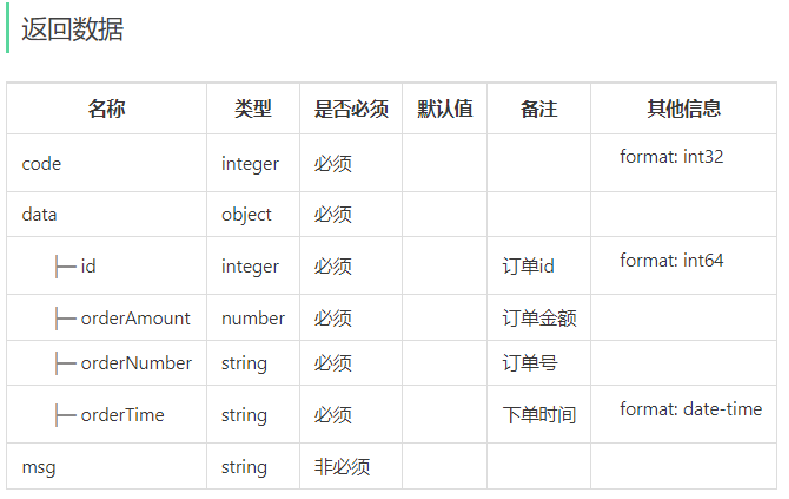 

在sky-pojo模块，OrderSubmitVO.java已定义

```java
package com.sky.vo;

import lombok.AllArgsConstructor;
import lombok.Builder;
import lombok.Data;
import lombok.NoArgsConstructor;
import java.io.Serializable;
import java.math.BigDecimal;
import java.time.LocalDateTime;

@Data
@Builder
@NoArgsConstructor
@AllArgsConstructor
public class OrderSubmitVO implements Serializable {
    //订单id
    private Long id;
    //订单号
    private String orderNumber;
    //订单金额
    private BigDecimal orderAmount;
    //下单时间
    private LocalDateTime orderTime;
}
```


#### 2.2.3 Controller层

**创建OrderController并提供用户下单方法：**

```java
package com.sky.controller.user;

import com.sky.dto.OrdersPaymentDTO;
import com.sky.dto.OrdersSubmitDTO;
import com.sky.result.PageResult;
import com.sky.result.Result;
import com.sky.service.OrderService;
import com.sky.vo.OrderPaymentVO;
import com.sky.vo.OrderSubmitVO;
import com.sky.vo.OrderVO;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.*;

/**
 * 订单
 */
@RestController("userOrderController")
@RequestMapping("/user/order")
@Slf4j
@Api(tags = "C端-订单接口")
public class OrderController {

    @Autowired
    private OrderService orderService;

    /**
     * 用户下单
     *
     * @param ordersSubmitDTO
     * @return
     */
    @PostMapping("/submit")
    @ApiOperation("用户下单")
    public Result<OrderSubmitVO> submit(@RequestBody OrdersSubmitDTO ordersSubmitDTO) {
        log.info("用户下单：{}", ordersSubmitDTO);
        OrderSubmitVO orderSubmitVO = orderService.submitOrder(ordersSubmitDTO);
        return Result.success(orderSubmitVO);
    } 

}
```


#### 2.2.4 Service层接口

**创建OrderService接口，并声明用户下单方法：**

```java
package com.sky.service;

import com.sky.dto.*;
import com.sky.vo.OrderSubmitVO;

public interface OrderService {

    /**
     * 用户下单
     * @param ordersSubmitDTO
     * @return
     */
    OrderSubmitVO submitOrder(OrdersSubmitDTO ordersSubmitDTO);
}
```


#### 2.2.5 Service层实现类

**创建OrderServiceImpl实现OrderService接口：**

```java
package com.sky.service.impl;

/**
 * 订单
 */
@Service
@Slf4j
public class OrderServiceImpl implements OrderService {
    @Autowired
    private OrderMapper orderMapper;
    @Autowired
    private OrderDetailMapper orderDetailMapper;
    @Autowired
    private ShoppingCartMapper shoppingCartMapper;
    @Autowired
    private AddressBookMapper addressBookMapper;


    /**
     * 用户下单
     *
     * @param ordersSubmitDTO
     * @return
     */
    @Transactional
    public OrderSubmitVO submitOrder(OrdersSubmitDTO ordersSubmitDTO) {
        //异常情况的处理（收货地址为空、超出配送范围、购物车为空）
        AddressBook addressBook = addressBookMapper.getById(ordersSubmitDTO.getAddressBookId());
        if (addressBook == null) {
            throw new AddressBookBusinessException(MessageConstant.ADDRESS_BOOK_IS_NULL);
        }

        Long userId = BaseContext.getCurrentId();
        ShoppingCart shoppingCart = new ShoppingCart();
        shoppingCart.setUserId(userId);

        //查询当前用户的购物车数据
        List<ShoppingCart> shoppingCartList = shoppingCartMapper.list(shoppingCart);
        if (shoppingCartList == null || shoppingCartList.size() == 0) {
            throw new ShoppingCartBusinessException(MessageConstant.SHOPPING_CART_IS_NULL);
        }

        //构造订单数据
        Orders order = new Orders();
        BeanUtils.copyProperties(ordersSubmitDTO,order);
        order.setPhone(addressBook.getPhone());
        order.setAddress(addressBook.getDetail());
        order.setConsignee(addressBook.getConsignee());
        order.setNumber(String.valueOf(System.currentTimeMillis()));
        order.setUserId(userId);
        order.setStatus(Orders.PENDING_PAYMENT);
        order.setPayStatus(Orders.UN_PAID);
        order.setOrderTime(LocalDateTime.now());

        //向订单表插入1条数据
        orderMapper.insert(order);

        //订单明细数据
        List<OrderDetail> orderDetailList = new ArrayList<>();
        for (ShoppingCart cart : shoppingCartList) {
            OrderDetail orderDetail = new OrderDetail();
            BeanUtils.copyProperties(cart, orderDetail);
            orderDetail.setOrderId(order.getId());
            orderDetailList.add(orderDetail);
        }

        //向明细表插入n条数据
        orderDetailMapper.insertBatch(orderDetailList);

        //清理购物车中的数据
        shoppingCartMapper.deleteByUserId(userId);

        //封装返回结果
        OrderSubmitVO orderSubmitVO = OrderSubmitVO.builder()
                .id(order.getId())
                .orderNumber(order.getNumber())
                .orderAmount(order.getAmount())
                .orderTime(order.getOrderTime())
                .build();

        return orderSubmitVO;
    }
    
}
```


#### 2.2.6 Mapper层

**创建OrderMapper接口和对应的xml映射文件：**

OrderMapper.java

```java
package com.sky.mapper;

@Mapper
public interface OrderMapper {
    /**
     * 插入订单数据
     * @param order
     */
    void insert(Orders order);
}

```

OrderMapper.xml

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN" "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.OrderMapper">

    <insert id="insert" parameterType="Orders" useGeneratedKeys="true" keyProperty="id">
        insert into orders
        (number, status, user_id, address_book_id, order_time, checkout_time, pay_method, pay_status, amount, remark,
         phone, address, consignee, estimated_delivery_time, delivery_status, pack_amount, tableware_number,
         tableware_status)
        values (#{number}, #{status}, #{userId}, #{addressBookId}, #{orderTime}, #{checkoutTime}, #{payMethod},
                #{payStatus}, #{amount}, #{remark}, #{phone}, #{address}, #{consignee},
                #{estimatedDeliveryTime}, #{deliveryStatus}, #{packAmount}, #{tablewareNumber}, #{tablewareStatus})
    </insert>
</mapper>

```

**创建OrderDetailMapper接口和对应的xml映射文件：**

OrderDetailMapper.java

```java
package com.sky.mapper;

import com.sky.entity.OrderDetail;
import java.util.List;

@Mapper
public interface OrderDetailMapper {

    /**
     * 批量插入订单明细数据
     * @param orderDetails
     */
    void insertBatch(List<OrderDetail> orderDetails);

}
```

OrderDetailMapper.xml

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN" "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.OrderDetailMapper">

    <insert id="insertBatch" parameterType="list">
        insert into order_detail
        (name, order_id, dish_id, setmeal_id, dish_flavor, number, amount, image)
        values
        <foreach collection="orderDetails" item="od" separator=",">
            (#{od.name},#{od.orderId},#{od.dishId},#{od.setmealId},#{od.dishFlavor},
             #{od.number},#{od.amount},#{od.image})
        </foreach>
    </insert>

</mapper>
```


### 下单校验、金额与事务（补充与勘误）

#### 1. 当前用户和地址必须先确认

原方法先getById检查地址存在，没有检查地址所属用户；同时直接从BaseContext取userId用于动态购物车查询。先拒绝缺失身份并使用当前用户限定地址：

```java
Long userId = BaseContext.getCurrentId();
if (userId == null || userId <= 0) {
    throw new IllegalStateException("缺少当前登录用户");
}
if (ordersSubmitDTO == null || ordersSubmitDTO.getAddressBookId() == null) {
    throw new AddressBookBusinessException(MessageConstant.ADDRESS_BOOK_IS_NULL);
}
AddressBook addressBook = addressBookMapper.getByIdAndUserId(
        ordersSubmitDTO.getAddressBookId(), userId);
if (addressBook == null) {
    throw new AddressBookBusinessException(MessageConstant.ADDRESS_BOOK_IS_NULL);
}
```

放在原submitOrder开头并替换原地址、userId变量声明，Mapper使用前面补充的方法。还需校验地址完整和配送范围、店铺营业状态；第05章页面提示打烊不能代替服务端下单检查。

#### 2. 客户端amount不能直接决定订单价格

BeanUtils复制DTO后，原order.amount和packAmount来自客户端，没有重新计算。应先从服务端商品记录或已定义报价核对价格、可售状态和规格，形成经验证的购物车快照，再算总额并覆盖拷贝值。

商品价格变化时要按约定提示重新确认或按已锁定报价结算；不能静默把旧购物车单价当作一定有效。以下示例仅计算已经核对的商品小计：

```java
BigDecimal goodsAmount = BigDecimal.ZERO;
for (ShoppingCart item : shoppingCartList) {
    if (item.getNumber() == null || item.getNumber() <= 0
            || item.getAmount() == null || item.getAmount().signum() < 0) {
        throw new IllegalArgumentException("购物车数量或价格不合法");
    }
    goodsAmount = goodsAmount.add(item.getAmount()
            .multiply(BigDecimal.valueOf(item.getNumber())));
}
// 在实际计费规则中加入服务端确认的费用与优惠后，得到最终serverTotal。
// 使用order.setAmount(serverTotal)覆盖DTO金额，再执行insert。
```

serverTotal不是此片段定义的变量，表示实际计费代码计算出的最终值。不要把这段小计算式误当成已实现全部计费，更不要直接把DTO.amount赋给它。

客户端amount可用来比较用户看到的价格是否已变化，不作为价格来源；不一致时按业务返回重新确认。packAmount、配送与餐具状态也需按服务端规则确定/验证。金额单位和小数精度统一用BigDecimal，避免double造成差异。

#### 3. 地址快照要完整，商品明细不要继承购物车主键

原order.address只取addressBook.detail，省市区名称没有拼入。保存订单地址时按实际字段组成完整配送文本；如果detail本来已含完整地址，要避免重复拼接。

BeanUtils.copyProperties(cart, orderDetail)会把购物车id也复制到明细id。原明细INSERT不写id，所以数据库仍生成新id；为避免对象语义混淆，可复制后 `orderDetail.setId(null)`，再设置orderId。

订单地址、电话、收货人和商品明细是下单时快照，后续修改地址或删除商品不应更改这些历史记录。

#### 4. 订单号和主键回填

原 `String.valueOf(System.currentTimeMillis())`在同毫秒、多线程或多实例下可能重复，不是可靠唯一订单号方案。按支付接口允许的字符与长度，使用合适的业务号生成器，并在orders.number上建立唯一约束。

OrderMapper.insert的useGeneratedKeys和keyProperty=id必须保留，主键回填后才给全部明细设置order_id。明细集合非空再insertBatch，集合名可显式固定：

```java
void insertBatch(@org.apache.ibatis.annotations.Param("orderDetails")
                 List<OrderDetail> orderDetails);
```

XML继续用collection="orderDetails"，namespace对齐OrderDetailMapper。原Mapper与Service部分代码省略imports，需补Orders、Mapper、事务注解、BeanUtils、LocalDateTime、ArrayList等实际使用类型。

#### 5. 三组写入处于同一个数据库事务

```text
insert orders → insert order_detail多条 → 删除本次购物车
    任一步写入失败并向外抛异常 → 全部回滚
```

原@Transactional正确表达了这组操作，保留代理调用和异常回滚。明细写入失败时，不应留下孤立订单或清空购物车；catch后返回成功会破坏失败语义。

事务不能自动阻止两个提交请求同时读取同一购物车并创建两个订单。需要结算请求幂等键、明确唯一约束及串行/锁定方案，重复提交返回同一业务结果，而不是仅换一个唯一订单号再下单一次。

原deleteByUserId清理当前用户全部购物车。读取购物车之后若另一个请求新增行或增数量，这次删除可能移除未包含在本订单中的商品；仅改成按读出的行id删除也不能解决同一行后来增加数量的问题。应明确结算快照、版本或按用户串行处理，将本次结算的条目与后续修改区分。

这组数据库事务不包含微信支付：不要把远程等待和支付过程都塞进submitOrder的数据库事务。下单成功但尚未付款是正常的业务阶段。


### 2.3 功能测试

> **PPT对照：** 第41页。

登录小程序，完成下单操作

下单操作时，同时会删除购物车中的数据

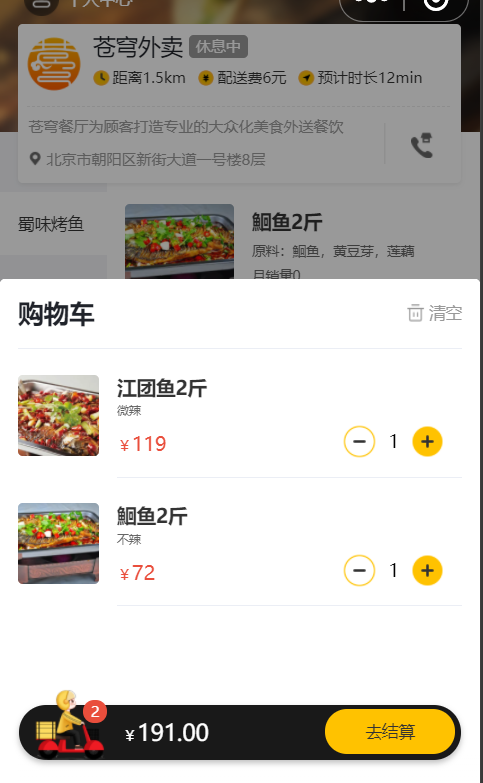 

**查看shopping_cart表：**

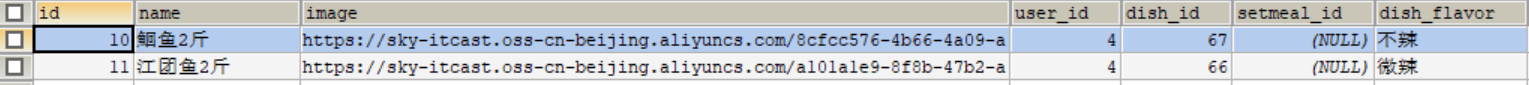 

**去结算-->去支付**

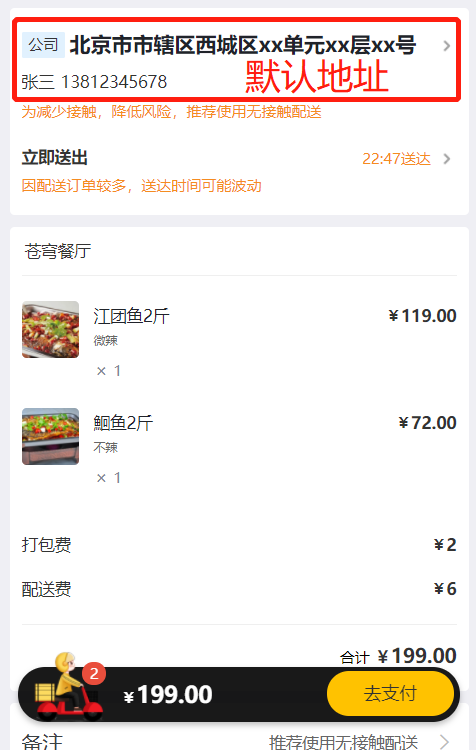 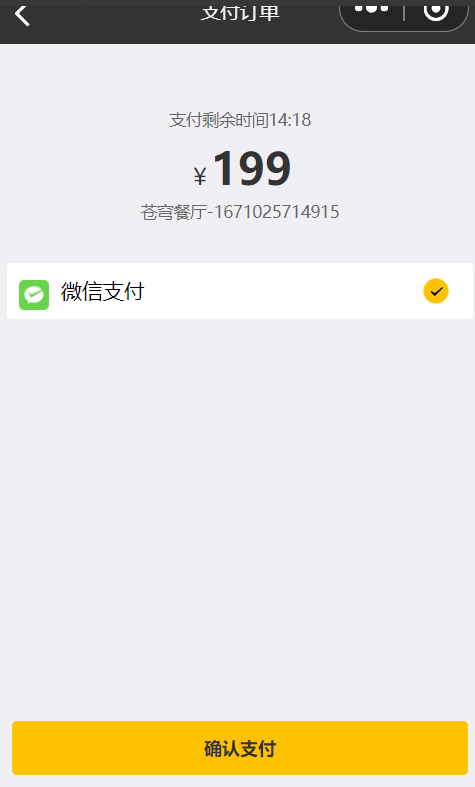 


**查看orders表：**

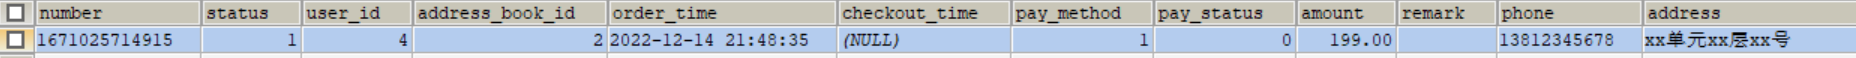

**查看order_detail表：**

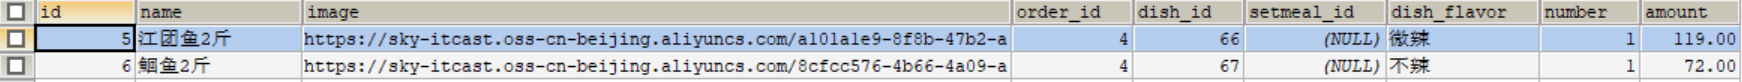 

**同时，购物车表中数据删除：**

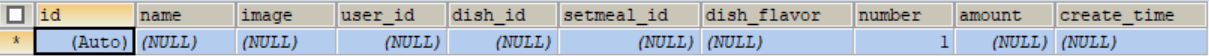


### 下单验收矩阵（补充）

| 场景 | 预期 |
| --- | --- |
| 有效地址与非空购物车提交 | orders一条，明细多条，待付款/未支付 |
| 核对id与number | 明细关联主键id，支付使用唯一number |
| 提交后购物车 | 只处理本次已提交内容，其他用户不变 |
| 空购物车 | 业务错误，无订单与明细 |
| 地址不存在或不属当前用户 | 拒绝，不使用其他用户地址 |
| 商品停售、规格无效、数量异常 | 按规则拒绝，不创建无效订单 |
| 客户端降低amount或packAmount | 服务端重新核算或拒绝，不按伪造金额结算 |
| 明细插入或清理发生异常 | 订单、明细和购物车修改全部回滚 |
| 重复提交/并发结算 | 按实现的幂等策略只产生预期订单 |
| 修改地址或商品之后看历史订单 | 原订单快照保持不变 |

用测试数据核对三张表与响应；验证失败回滚时故意制造可控的明细写入错误，不在真实业务数据上试验。界面跳到支付页仅说明前端跳转，不能证明总额、归属和事务都正确。


### 2.4 代码提交

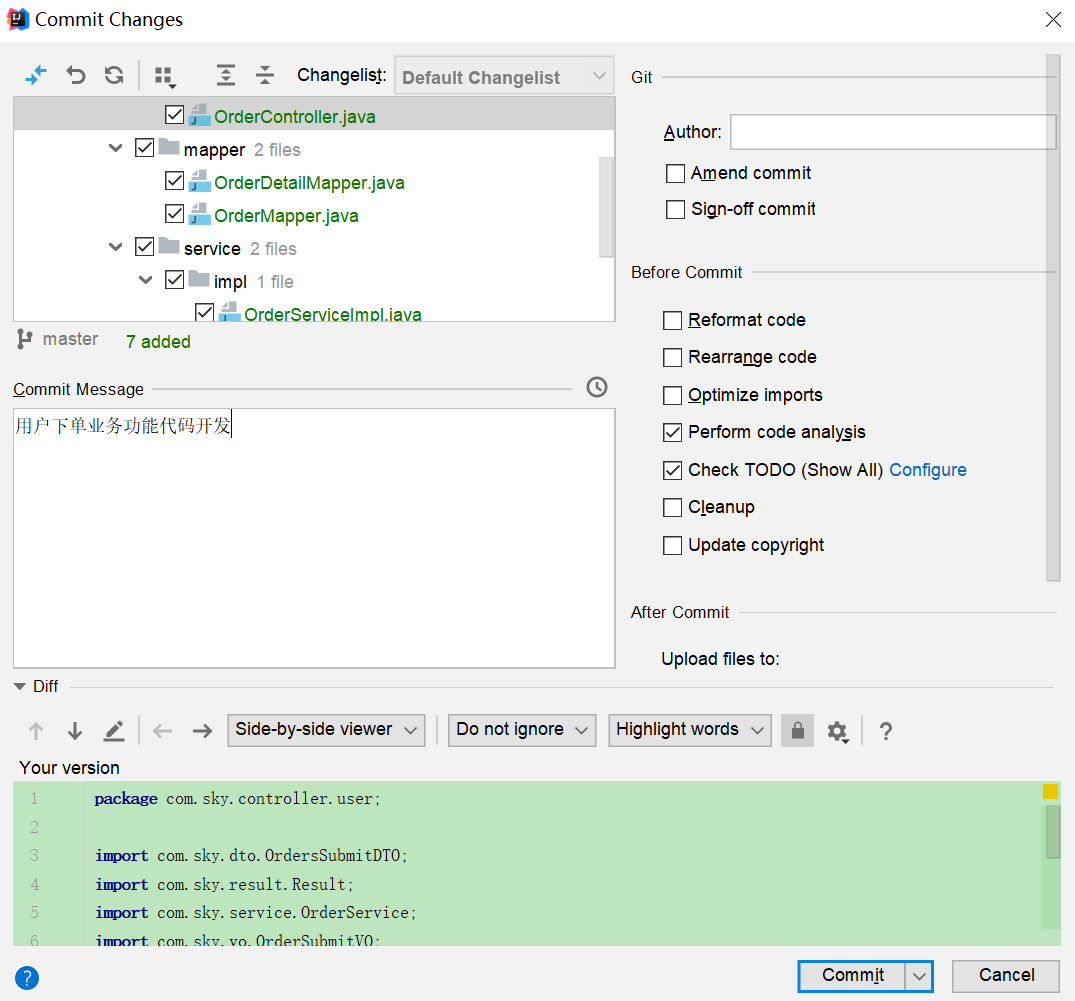 

后续步骤和其它功能代码提交一致，不再赘述。


## 3. 订单支付

> **PPT对照：** 第43—56页。


### 3.1 微信支付介绍

> **PPT对照：** 第44—48页。

前面的课程已经实现了用户下单，那接下来就是订单支付，就是完成付款功能。支付大家应该都不陌生了，在现实生活中经常购买商品并且使用支付功能来付款，在付款的时候可能使用比较多的就是微信支付和支付宝支付了。在苍穹外卖项目中，选择的就是**微信支付**这种支付方式。

要实现微信支付就需要注册微信支付的一个商户号，这个商户号是必须要有一家企业并且有正规的营业执照。只有具备了这些资质之后，才可以去注册商户号，才能开通支付权限。

个人不具备这种资质，所以我们在学习微信支付时，最重要的是了解微信支付的流程，并且能够阅读微信官方提供的接口文档，能够和第三方支付平台对接起来就可以了。

**微信支付产品：**

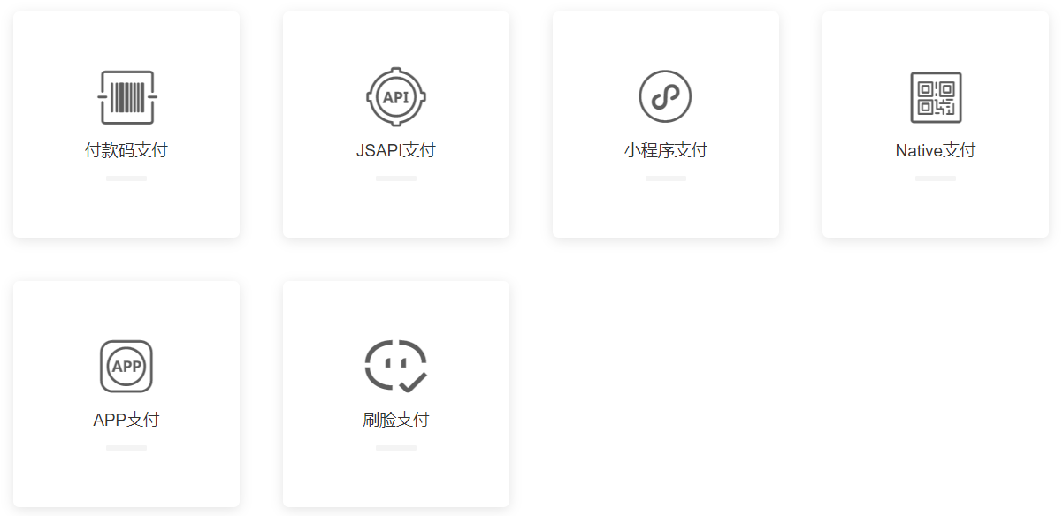 

本项目选择**小程序支付**

参考：https://pay.weixin.qq.com/static/product/product_index.shtml


**微信支付接入流程：**

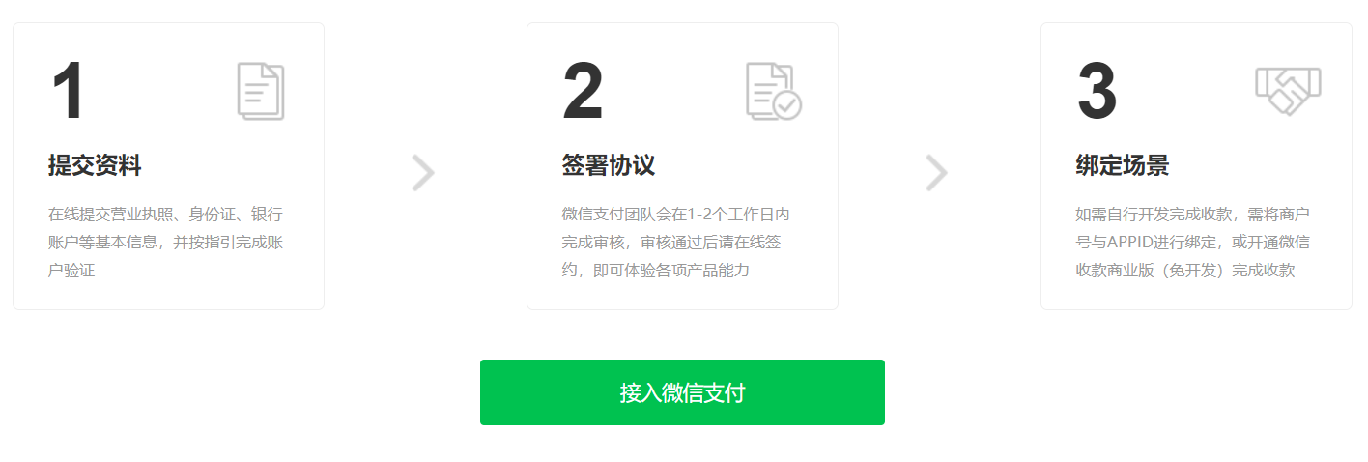 


**微信小程序支付时序图：**

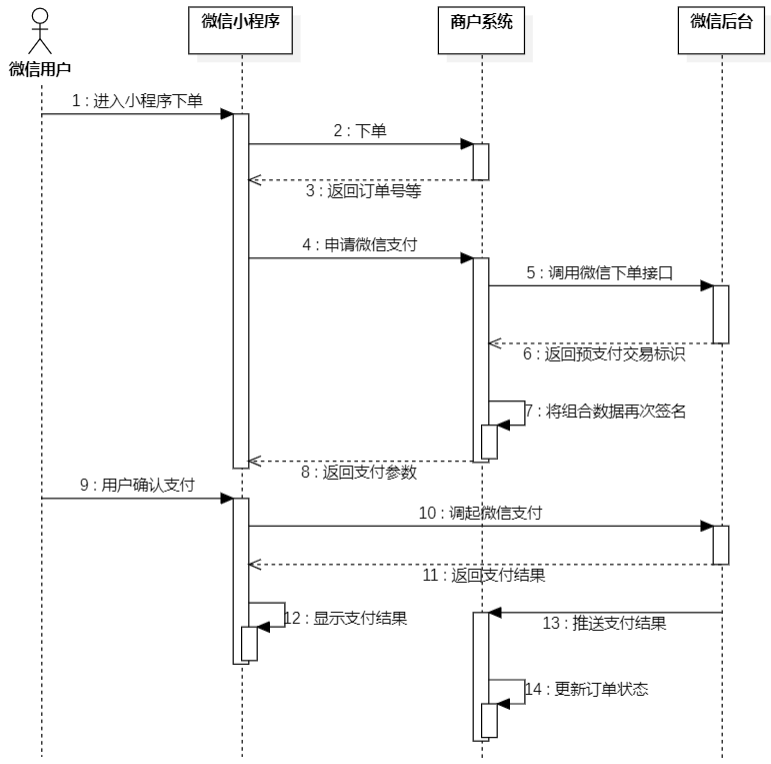 


**微信支付相关接口：**

**JSAPI下单：**商户系统调用该接口在微信支付服务后台生成预支付交易单(对应时序图的第5步)

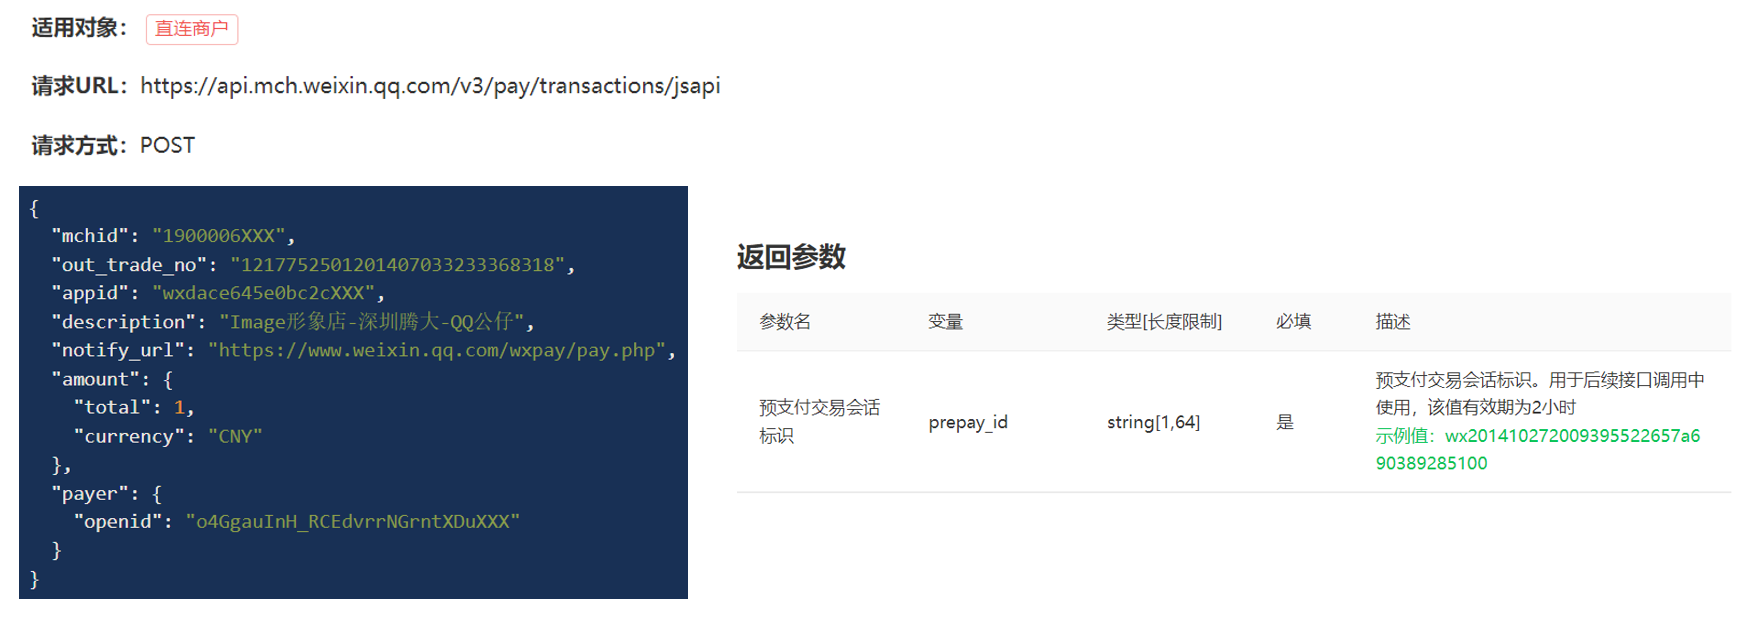


**微信小程序调起支付：**通过JSAPI下单接口获取到发起支付的必要参数prepay_id，然后使用微信支付提供的小程序方法调起小程序支付(对应时序图的第10步)

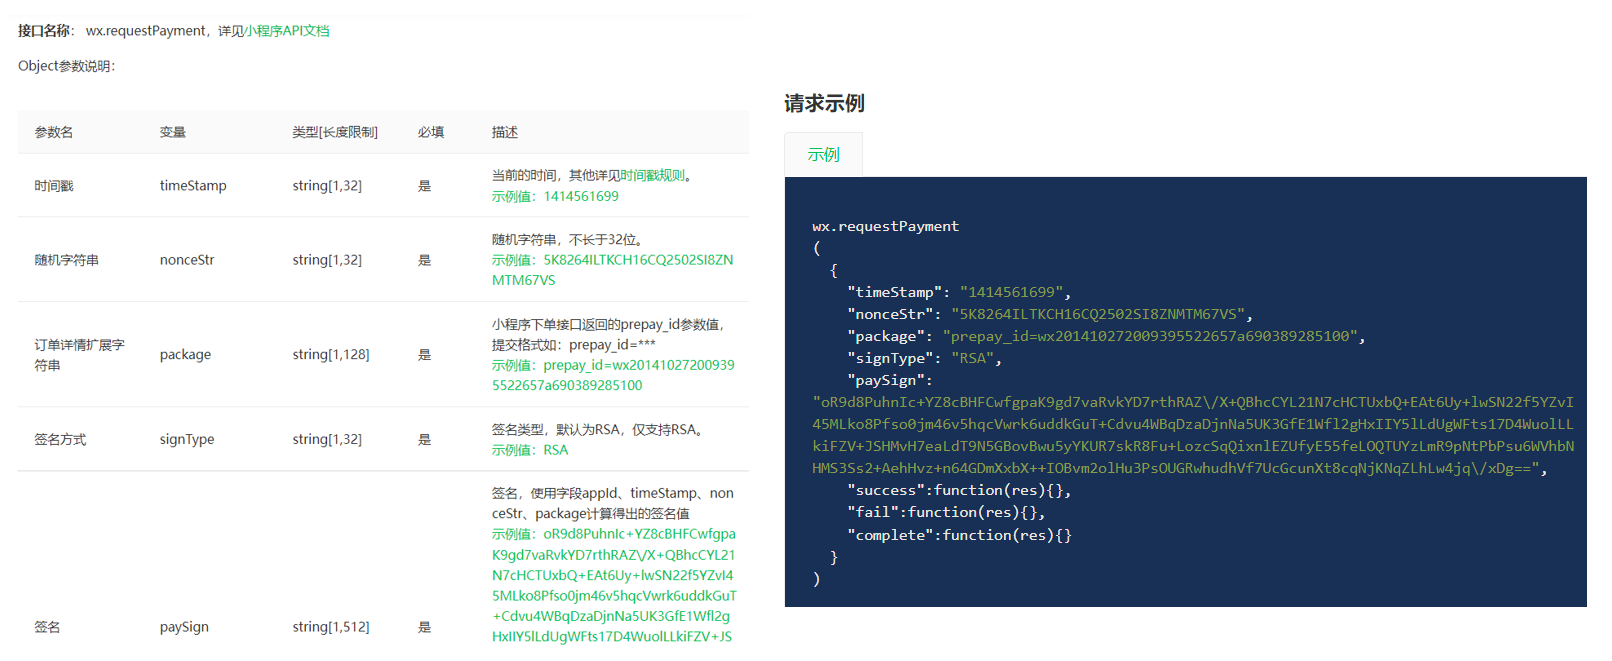


### 预支付单与业务订单的区别（补充）

我们先在orders生成业务订单，再调用微信JSAPI接口生成预支付交易单，取得prepay_id。小程序用后端返回的签名参数调起wx.requestPayment，不直接携带商户私钥调用微信下单。

常见调起支付参数包含timeStamp、nonceStr、package、signType、paySign，其中package按支付接口规则包含prepay_id。Java里package是关键字，所以原VO用packageStr承接，前端再映射到wx.requestPayment所需的package字段。

业务订单number对应商户out_trade_no；transaction_id由微信生成，两者不同。用户支付取消、网络超时或前端退出，并不能仅凭前端回调推断服务端交易最终状态，应通过可信通知或主动查单确认。

原文按教学背景概括商户资质，实际接入条件以对应支付产品与平台审核要求为准。本章重点理解接口和状态链路，不认为使用老师的商户参数即可完成自己的真实支付接入。


### 3.2 微信支付准备工作

> **PPT对照：** 第50—52页。

#### 3.2.1 如何保证数据安全？

完成微信支付有两个关键的步骤：

**第一个**就是需要在商户系统当中调用微信后台的一个下单接口，就是生成预支付交易单。

**第二个**就是支付成功之后微信后台会给推送消息。

这两个接口数据的安全性，要求其实是非常高的。

**解决：**微信提供的方式就是对数据进行加密、解密、签名多种方式。要完成数据加密解密，需要提前准备相应的一些文件，其实就是一些证书。

**获取微信支付平台证书、商户私钥文件：**

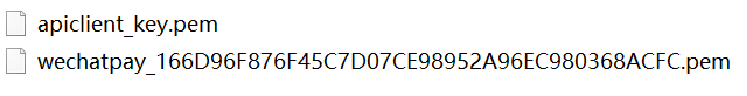 

在后绪程序开发过程中，就会使用到这两个文件，需要提前把这两个文件准备好。


#### 3.2.2 如何调用到商户系统？

微信后台会调用到商户系统给推送支付的结果，在这里我们就会遇到一个问题，就是微信后台怎么就能调用到我们这个商户系统呢？因为这个调用过程，其实本质上也是一个HTTP请求。

目前，商户系统它的ip地址就是当前自己电脑的ip地址，只是一个局域网内的ip地址，微信后台无法调用到。

**解决：**内网穿透。通过**cpolar软件**可以获得一个临时域名，而这个临时域名是一个公网ip，这样，微信后台就可以请求到商户系统了。

**cpolar软件的使用：**

**1). 下载与安装**

下载地址：https://dashboard.cpolar.com/get-started

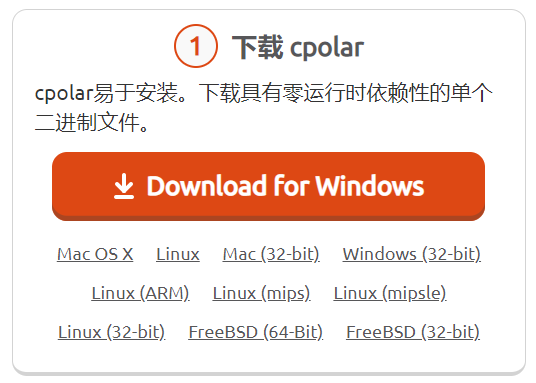 

在资料中已提供，可无需下载。

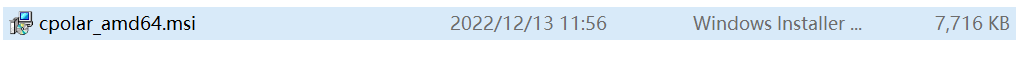 

安装过程中，一直下一步即可，不再演示。

**2). cpolar指定authtoken**

复制authtoken：

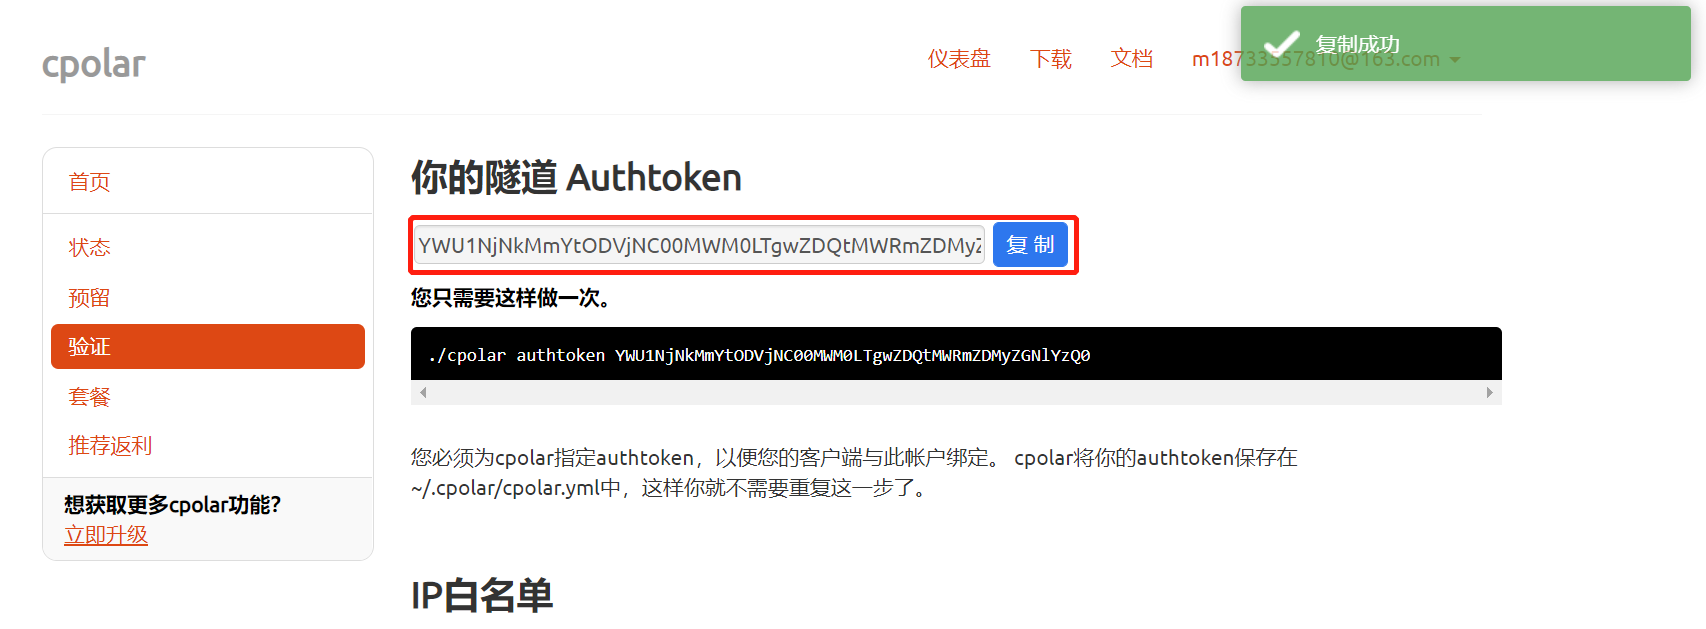 

执行命令：

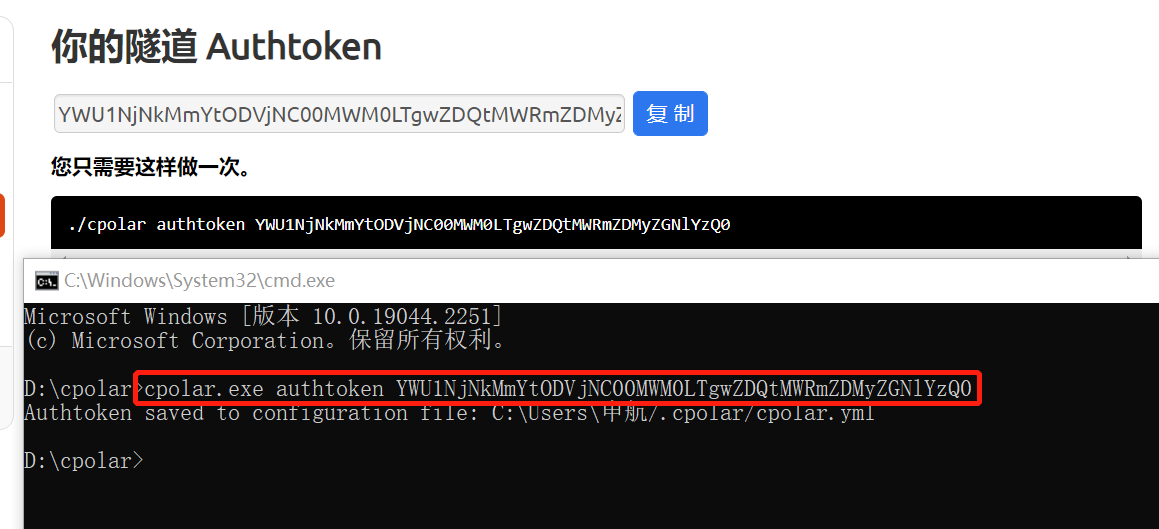 


**3). 获取临时域名**

执行命令：

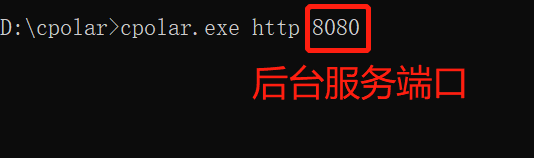 

获取域名：

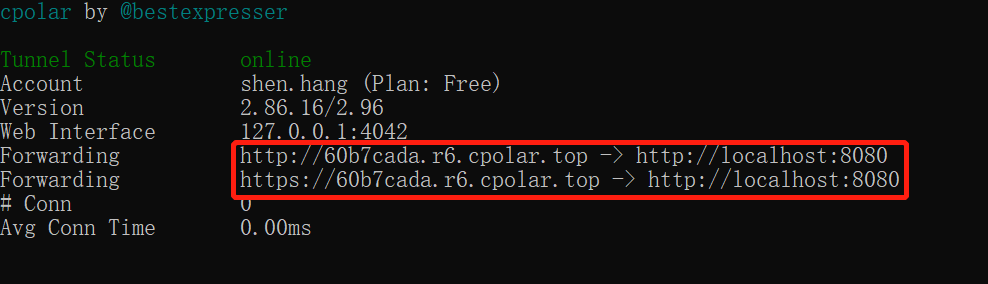 


**4). 验证临时域名有效性**

**访问接口文档**

使用localhost:8080访问

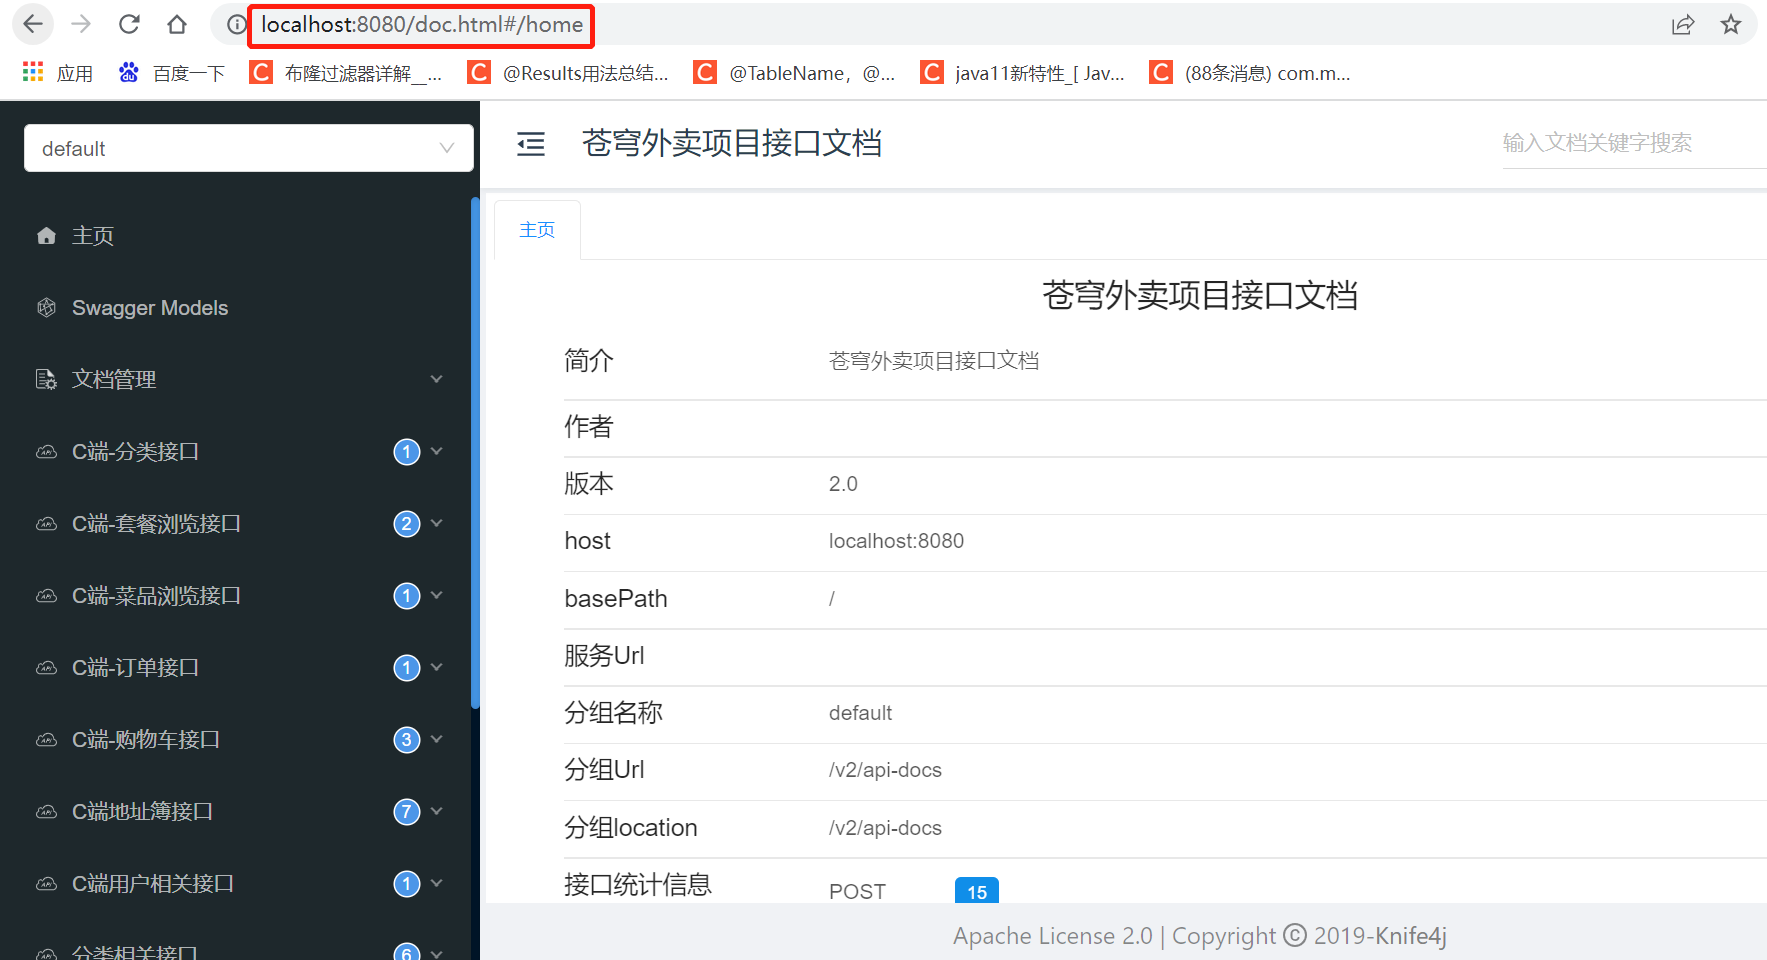 

使用临时域名访问

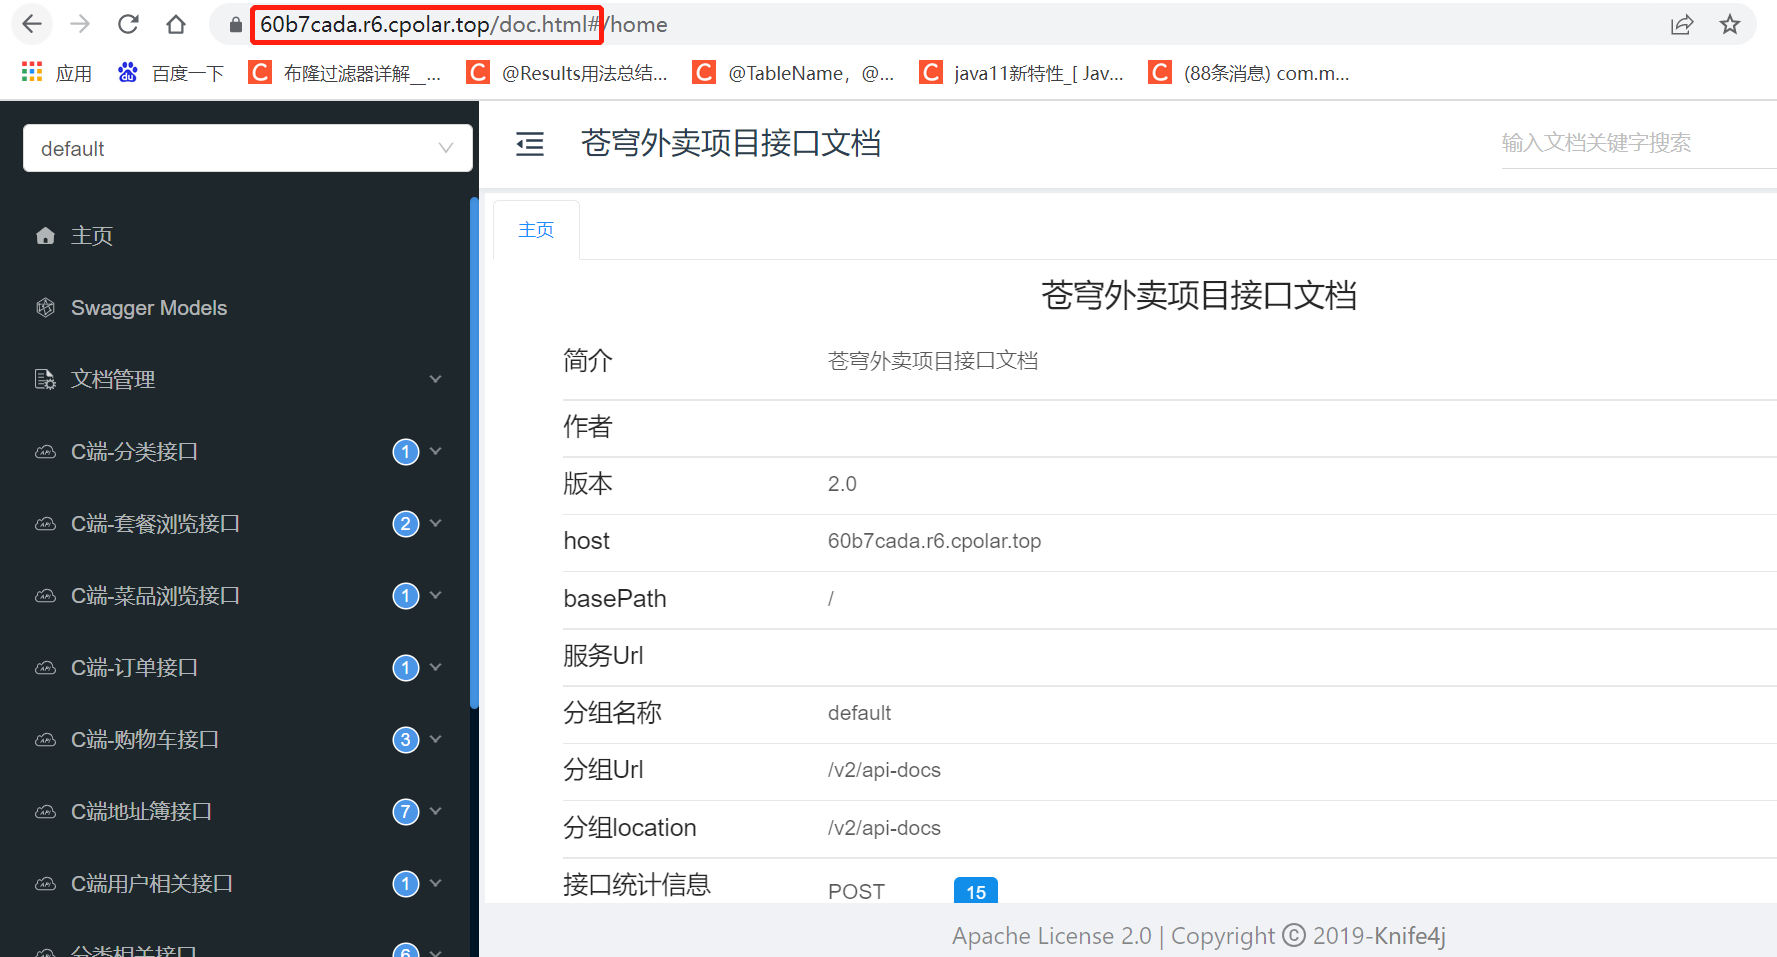 

证明临时域名生效。


### 凭据、验签与可达回调（补充与勘误）

| 配置/文件 | 主要用途 |
| --- | --- |
| appid与mchid | 标识小程序和商户，需具备正确关联关系 |
| 商户私钥与商户证书序列号 | 为商户发往微信的请求及相应调起参数签名 |
| 微信支付平台证书/平台公钥方案 | 按实际接入方案验证微信签名，需维护有效版本 |
| API v3密钥 | 解密通知resource等对应密文，不等于小程序AppSecret |
| notifyUrl | 微信通知我们服务端的完整地址 |

签名用于校验消息来源和完整性，解密用于读取密文内容，HTTPS用于传输连接；这些职责不同。原“准备证书就完成安全处理”的描述不能替代代码中真正执行验签。

平台证书与商户私钥不是同一个文件，API v3密钥与第06章登录AppSecret也不是同一个值。按商户当前使用的证书或平台公钥方案接入，不直接复制旧证书文件名与序列号。

内网穿透把公网入口转发到本地服务，“临时域名是一个公网ip”应理解为它提供可公开访问的域名入口，域名本身不是IP地址。实际通知地址还要包含正确路径，例如自己的HTTPS入口加 `/notify/paySuccess`。

课程YAML的notifyUrl示例指向微信域名中的演示路径，不是自己的商户后端，不能照填。临时域名变化后要更新配置与预支付请求中的通知地址；能打开doc.html不表示POST回调路由、签名验证和业务处理已全部可用。

开发测试只暴露确实需要的入口，保留业务接口鉴权。这里整理讲义，不会启动穿透、公开本地服务、注册商户或发起实际扣款。退款通知配置在本章仅准备，退款处理不是当前代码已经实现的功能。


### 3.3 代码导入

> **PPT对照：** 第54—56页，详细支付与通知实现由讲义展开。

导入资料中的微信支付功能代码即可

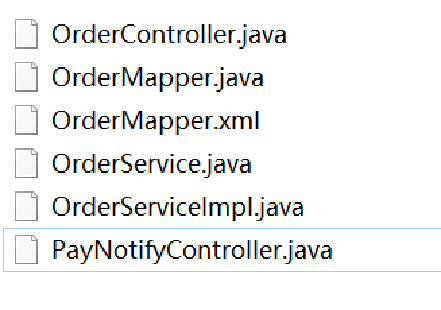 

#### 3.3.1 微信支付相关配置

application-dev.yml

```yaml
sky:
  wechat:
    appid: <填写你的小程序AppID>
    secret: <填写你的小程序AppSecret>
    mchid : <填写你的微信支付商户号>
    mchSerialNo: <填写你的商户证书序列号>
    privateKeyFilePath: <填写你的商户私钥文件路径>
    apiV3Key: <填写你的API_v3密钥>
    weChatPayCertFilePath: <填写你的微信支付平台证书文件路径>
    notifyUrl: <填写你的HTTPS支付通知地址>
    refundNotifyUrl: <填写你的HTTPS退款通知地址>
```

application.yml

```yaml
sky:
  wechat:
    appid: ${sky.wechat.appid}
    secret: ${sky.wechat.secret}
    mchid : ${sky.wechat.mchid}
    mchSerialNo: ${sky.wechat.mchSerialNo}
    privateKeyFilePath: ${sky.wechat.privateKeyFilePath}
    apiV3Key: ${sky.wechat.apiV3Key}
    weChatPayCertFilePath: ${sky.wechat.weChatPayCertFilePath}
    notifyUrl: ${sky.wechat.notifyUrl}
    refundNotifyUrl: ${sky.wechat.refundNotifyUrl}

```

WeChatProperties.java：读取配置(已定义)

```java
package com.sky.properties;

import lombok.Data;
import org.springframework.beans.factory.annotation.Value;
import org.springframework.boot.context.properties.ConfigurationProperties;
import org.springframework.stereotype.Component;

@Component
@ConfigurationProperties(prefix = "sky.wechat")
@Data
public class WeChatProperties {

    private String appid; //小程序的appid
    private String secret; //小程序的秘钥
    private String mchid; //商户号
    private String mchSerialNo; //商户API证书的证书序列号
    private String privateKeyFilePath; //商户私钥文件
    private String apiV3Key; //证书解密的密钥
    private String weChatPayCertFilePath; //平台证书
    private String notifyUrl; //支付成功的回调地址
    private String refundNotifyUrl; //退款成功的回调地址
}
```


#### 3.3.2 Mapper层

**在OrderMapper.java中添加getByNumberAndUserId和update两个方法**

```java
	/**
     * 根据订单号和用户id查询订单
     * @param orderNumber
     * @param userId
     */
    @Select("select * from orders where number = #{orderNumber} and user_id= #{userId}")
    Orders getByNumberAndUserId(String orderNumber, Long userId);

    /**
     * 修改订单信息
     * @param orders
     */
    void update(Orders orders);
```

**在OrderMapper.xml中添加**

```xml
<update id="update" parameterType="com.sky.entity.Orders">
        update orders
        <set>
            <if test="cancelReason != null and cancelReason!='' ">
                cancel_reason=#{cancelReason},
            </if>
            <if test="rejectionReason != null and rejectionReason!='' ">
                rejection_reason=#{rejectionReason},
            </if>
            <if test="cancelTime != null">
                cancel_time=#{cancelTime},
            </if>
            <if test="payStatus != null">
                pay_status=#{payStatus},
            </if>
            <if test="payMethod != null">
                pay_method=#{payMethod},
            </if>
            <if test="checkoutTime != null">
                checkout_time=#{checkoutTime},
            </if>
            <if test="status != null">
                status = #{status},
            </if>
            <if test="deliveryTime != null">
                delivery_time = #{deliveryTime}
            </if>
        </set>
        where id = #{id}
</update>
```


#### 3.3.3 Service层

**在OrderService.java中添加payment和paySuccess两个方法定义**

```java
	/**
     * 订单支付
     * @param ordersPaymentDTO
     * @return
     */
    OrderPaymentVO payment(OrdersPaymentDTO ordersPaymentDTO) throws Exception;

    /**
     * 支付成功，修改订单状态
     * @param outTradeNo
     */
    void paySuccess(String outTradeNo);
```

**在OrderServiceImpl.java中实现payment和paySuccess两个方法**

```java
 	@Autowired
    private UserMapper userMapper;
	@Autowired
    private WeChatPayUtil weChatPayUtil;
    /**
     * 订单支付
     *
     * @param ordersPaymentDTO
     * @return
     */
    public OrderPaymentVO payment(OrdersPaymentDTO ordersPaymentDTO) throws Exception {
        // 当前登录用户id
        Long userId = BaseContext.getCurrentId();
        User user = userMapper.getById(userId);

        //调用微信支付接口，生成预支付交易单
        JSONObject jsonObject = weChatPayUtil.pay(
                ordersPaymentDTO.getOrderNumber(), //商户订单号
                new BigDecimal(0.01), //支付金额，单位 元
                "苍穹外卖订单", //商品描述
                user.getOpenid() //微信用户的openid
        );

        if (jsonObject.getString("code") != null && jsonObject.getString("code").equals("ORDERPAID")) {
            throw new OrderBusinessException("该订单已支付");
        }

        OrderPaymentVO vo = jsonObject.toJavaObject(OrderPaymentVO.class);
        vo.setPackageStr(jsonObject.getString("package"));

        return vo;
    }

    /**
     * 支付成功，修改订单状态
     *
     * @param outTradeNo
     */
    public void paySuccess(String outTradeNo) {
        // 当前登录用户id
        Long userId = BaseContext.getCurrentId();

        // 根据订单号查询当前用户的订单
        Orders ordersDB = orderMapper.getByNumberAndUserId(outTradeNo, userId);

        // 根据订单id更新订单的状态、支付方式、支付状态、结账时间
        Orders orders = Orders.builder()
                .id(ordersDB.getId())
                .status(Orders.TO_BE_CONFIRMED)
                .payStatus(Orders.PAID)
                .checkoutTime(LocalDateTime.now())
                .build();

        orderMapper.update(orders);
    }
```


#### 3.3.4 Controller层

**在OrderController.java中添加payment方法**

```java
 	/**
     * 订单支付
     *
     * @param ordersPaymentDTO
     * @return
     */
    @PutMapping("/payment")
    @ApiOperation("订单支付")
    public Result<OrderPaymentVO> payment(@RequestBody OrdersPaymentDTO ordersPaymentDTO) throws Exception {
        log.info("订单支付：{}", ordersPaymentDTO);
        OrderPaymentVO orderPaymentVO = orderService.payment(ordersPaymentDTO);
        log.info("生成预支付交易单：{}", orderPaymentVO);
        return Result.success(orderPaymentVO);
    }
```

PayNotifyController.java

```java
package com.sky.controller.notify;

import com.alibaba.druid.support.json.JSONUtils;
import com.alibaba.fastjson.JSON;
import com.alibaba.fastjson.JSONObject;
import com.sky.annotation.IgnoreToken;
import com.sky.properties.WeChatProperties;
import com.sky.service.OrderService;
import com.wechat.pay.contrib.apache.httpclient.util.AesUtil;
import lombok.extern.slf4j.Slf4j;
import org.apache.http.entity.ContentType;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;
import javax.servlet.http.HttpServletRequest;
import javax.servlet.http.HttpServletResponse;
import java.io.BufferedReader;
import java.nio.charset.StandardCharsets;
import java.util.HashMap;

/**
 * 支付回调相关接口
 */
@RestController
@RequestMapping("/notify")
@Slf4j
public class PayNotifyController {
    @Autowired
    private OrderService orderService;
    @Autowired
    private WeChatProperties weChatProperties;

    /**
     * 支付成功回调
     *
     * @param request
     */
    @RequestMapping("/paySuccess")
    public void paySuccessNotify(HttpServletRequest request, HttpServletResponse response) throws Exception {
        //读取数据
        String body = readData(request);
        log.info("支付成功回调：{}", body);

        //数据解密
        String plainText = decryptData(body);
        log.info("解密后的文本：{}", plainText);

        JSONObject jsonObject = JSON.parseObject(plainText);
        String outTradeNo = jsonObject.getString("out_trade_no");//商户平台订单号
        String transactionId = jsonObject.getString("transaction_id");//微信支付交易号

        log.info("商户平台订单号：{}", outTradeNo);
        log.info("微信支付交易号：{}", transactionId);

        //业务处理，修改订单状态、来单提醒
        orderService.paySuccess(outTradeNo);

        //给微信响应
        responseToWeixin(response);
    }

    /**
     * 读取数据
     *
     * @param request
     * @return
     * @throws Exception
     */
    private String readData(HttpServletRequest request) throws Exception {
        BufferedReader reader = request.getReader();
        StringBuilder result = new StringBuilder();
        String line = null;
        while ((line = reader.readLine()) != null) {
            if (result.length() > 0) {
                result.append("\n");
            }
            result.append(line);
        }
        return result.toString();
    }

    /**
     * 数据解密
     *
     * @param body
     * @return
     * @throws Exception
     */
    private String decryptData(String body) throws Exception {
        JSONObject resultObject = JSON.parseObject(body);
        JSONObject resource = resultObject.getJSONObject("resource");
        String ciphertext = resource.getString("ciphertext");
        String nonce = resource.getString("nonce");
        String associatedData = resource.getString("associated_data");

        AesUtil aesUtil = new AesUtil(weChatProperties.getApiV3Key().getBytes(StandardCharsets.UTF_8));
        //密文解密
        String plainText = aesUtil.decryptToString(associatedData.getBytes(StandardCharsets.UTF_8),
                nonce.getBytes(StandardCharsets.UTF_8),
                ciphertext);

        return plainText;
    }

    /**
     * 给微信响应
     * @param response
     */
    private void responseToWeixin(HttpServletResponse response) throws Exception{
        response.setStatus(200);
        HashMap<Object, Object> map = new HashMap<>();
        map.put("code", "SUCCESS");
        map.put("message", "SUCCESS");
        response.setHeader("Content-type", ContentType.APPLICATION_JSON.toString());
        response.getOutputStream().write(JSONUtils.toJSONString(map).getBytes(StandardCharsets.UTF_8));
        response.flushBuffer();
    }
}
```


### 支付金额、回调上下文与幂等（重点勘误）

#### 1. 先补齐依赖与配置

原支付实现使用初始工程的WeChatPayUtil、WeChatProperties、OrdersPaymentDTO、OrderPaymentVO和UserMapper.getById；讲义没有提供WeChatPayUtil完整代码。需要导入实际课程工具类及其微信支付SDK依赖，不能仅贴Controller就认为已经完成签名与HTTP调用。

UserMapper在第06章只展示getByOpenid和insert，本章又调用getById；工程缺少时补：

```java
@org.apache.ibatis.annotations.Select("select * from user where id = #{id}")
User getById(@org.apache.ibatis.annotations.Param("id") Long id);
```

原订单查询有两个参数，推荐明确命名，不依赖编译器参数名：

```java
@Select("select * from orders where number = #{orderNumber} and user_id = #{userId}")
Orders getByNumberAndUserId(
        @org.apache.ibatis.annotations.Param("orderNumber") String orderNumber,
        @org.apache.ibatis.annotations.Param("userId") Long userId);
```

微信配置与第06章同属sky.wechat，扩展原WeChatProperties，不新建另一份同名Bean，也不覆盖原登录功能。merchant、证书/私钥路径、API v3密钥和回调地址各自对应自己的环境。

配置可以使用环境变量填写，以下是一套替代示例，放入实际启用的配置文件；不要同时保留会覆盖它的同名硬编码配置：

```yaml
sky:
  wechat:
    appid: ${WECHAT_APP_ID}
    secret: ${WECHAT_APP_SECRET}
    mchid: ${WECHAT_MCH_ID}
    mchSerialNo: ${WECHAT_MCH_SERIAL_NO}
    privateKeyFilePath: ${WECHAT_PRIVATE_KEY_PATH}
    apiV3Key: ${WECHAT_API_V3_KEY}
    weChatPayCertFilePath: ${WECHAT_PAY_CERT_PATH}
    notifyUrl: ${WECHAT_PAY_NOTIFY_URL}
    refundNotifyUrl: ${WECHAT_REFUND_NOTIFY_URL}
```

原@Data的toString可能包含这些配置，普通日志不输出整个配置对象。私钥文件和API v3密钥留在后端受控位置，不进入小程序包或仓库。

#### 2. 发起支付必须先查当前用户的订单

原payment只查当前用户，然后拿客户端orderNumber调用微信；没有验证订单存在、归属、状态或金额。固定 `new BigDecimal(0.01)`仅是教学测试金额，不能用于真实订单收费。

在原payment开头检查当前用户、DTO与订单号，查询自己的订单并确认待付款、未支付；然后使用订单已确认的金额：

```java
Long userId = BaseContext.getCurrentId();
if (userId == null || userId <= 0 || ordersPaymentDTO == null
        || !org.springframework.util.StringUtils.hasText(ordersPaymentDTO.getOrderNumber())) {
    throw new OrderBusinessException("支付参数或登录身份不合法");
}
Orders order = orderMapper.getByNumberAndUserId(
        ordersPaymentDTO.getOrderNumber(), userId);
if (order == null) {
    throw new OrderBusinessException("订单不存在或无权访问");
}
if (!Integer.valueOf(Orders.PENDING_PAYMENT).equals(order.getStatus())
        || !Integer.valueOf(Orders.UN_PAID).equals(order.getPayStatus())) {
    throw new OrderBusinessException("订单不处于可支付状态");
}
User user = userMapper.getById(userId);
if (user == null || !org.springframework.util.StringUtils.hasText(user.getOpenid())) {
    throw new OrderBusinessException("支付用户信息不完整");
}
if (order.getAmount() == null || order.getAmount().signum() <= 0) {
    throw new OrderBusinessException("订单金额不合法");
}
JSONObject jsonObject = weChatPayUtil.pay(
        order.getNumber(), order.getAmount(), "苍穹外卖订单", user.getOpenid());
```

这是原payment的前半段替换；后面继续校验微信结果并构建OrderPaymentVO，不重复声明原user和jsonObject变量。只处理ORDERPAID不够，还需处理超时、空结果、其他错误码和缺少有效预支付参数。

工具类pay原约定输入金额为元，微信API金额字段按对应接口通常为分。核对工具类转换是否精确、只转换一次；转换示意：

```java
int totalFen = order.getAmount().movePointRight(2).intValueExact();
```

intValueExact会拒绝不能精确表示为整数分的金额或溢出；不要用double乘100或直接截断小数。核对币种与费用规则，也不要把客户端金额重新传到支付工具绕过前面的订单检查。

支付发起可能与订单取消竞争，应定义订单支付尝试、关单和状态变化策略。给payment方法加一个长事务不能把微信远程交易和数据库状态合成同一个原子动作。

#### 3. 微信通知里没有当前登录用户

原PayNotifyController接收微信服务端回调，没有小程序用户JWT；路径又在/notify下。此时BaseContext通常为null，原paySuccess却执行getByNumberAndUserId(outTradeNo, null)，查不到订单后getId发生空指针。

不能用固定userId、放宽用户端鉴权或让前端补一个userId来修正。可信回调应在验证通知后，按唯一商户订单号查本地订单，用户归属从订单记录取得。

回调可增加独立Mapper查询：

```java
@Select("select * from orders where number = #{orderNumber}")
Orders getByNumber(@org.apache.ibatis.annotations.Param("orderNumber") String orderNumber);
```

仅新增该方法还不足以安全完成回调，必须先完成下面的通知验证。用户主动发起支付仍用getByNumberAndUserId，不能把两个查询场景混成任意订单都能被用户操作。

#### 4. 解密成功不等于全部校验完成

原Controller读取body、AES-GCM解密后直接取out_trade_no并更新订单，缺少通知签名验证、交易状态与金额/商户校验。应使用实际微信支付SDK的通知解析和验签能力，或按当前官方协议实现完整验证。

```text
读取原始通知body与微信签名headers
    → 按有效平台证书/公钥校验签名、时间戳与通知规则
    → 按API v3协议解密resource
    → 检查通知事件与trade_state是否为成功支付
    → 检查appid、mchid、out_trade_no、transaction_id
    → 按订单号查本地订单
    → 核对通知应收total/币种与本地订单（含优惠时区分实际支付金额字段）
    → 幂等更新与保存交易关联 → 处理成功后确认通知
```

校验金额按对应支付接口的字段语义进行，不能无条件把payer_total当成订单总额。不要只相信字段名字里含“成功”，失败、取消或其他事件不应被当作支付成功。

原readData逐行读取再拼换行会改变原始body在某些情况的字节内容；验签需要使用协议定义的原始请求体，读取一次并原样保存给验证器，不重排JSON、不重写换行。验证器也应处理有限的请求体大小与错误格式。

`associated_data`等字段按协议和SDK规则处理，原对null直接getBytes可能空指针。默认不用在日志打印完整通知和解密后的用户、交易资料，只保留必要的订单号、事件id或错误分类。

通知确认使用微信接口规定的响应，不照搬自己业务接口的Result包装。原200加SUCCESS是课程示例，实际按接入版本的成功确认与失败重试规则实现；数据库业务处理成功或识别已成功重复通知后才确认，失败不能先确认再丢弃处理。

#### 5. 支付回调必须幂等，不能重置后续订单状态

微信通知可能重复或并发到达。原每次直接把status改成待接单，可能把已经接单、派送甚至完成的订单重置回去，并不断覆盖checkoutTime。

Mapper应在数据库中限制状态迁移，只允许从待付款且未支付变为待接单且已支付。例如增加以下方法；paidAt来自已验证的交易成功时间并按业务统一时间规则转换，或使用明确的本地记录时间规则：

```java
@org.apache.ibatis.annotations.Update(
    "update orders set status = 2, pay_status = 1, checkout_time = #{paidAt} " +
    "where id = #{id} and status = 1 and pay_status = 0 " +
    "and amount = #{expectedAmount}")
int markPaidIfPending(
        @org.apache.ibatis.annotations.Param("id") Long id,
        @org.apache.ibatis.annotations.Param("expectedAmount") java.math.BigDecimal expectedAmount,
        @org.apache.ibatis.annotations.Param("paidAt") java.time.LocalDateTime paidAt);
```

SQL数值1、2与原Orders常量对应，后续状态扩展时保持统一。expectedAmount由经验证的通知与本地订单核对结果确定，不能来自用户随意提交的字段。

影响1行表示本次完成迁移；影响0行需要重新核对订单及已保存的交易关联：同一已确认交易的重复通知可正常确认，不再改状态；不存在、金额不符、不同交易、已取消等情况走明确的异常或对账处理。

实际需要保存transaction_id、通知事件id或支付尝试记录并加唯一约束；原orders表没有这些字段，扩展时可增加支付记录表，不假装调用上述一条SQL已实现完整支付对账。订单已取消但微信确认已扣款时，不能忽略通知或自动复活订单，应按业务补偿/退款规则处理。

修改订单与保存支付记录应放在本地事务中。来单提醒等副作用只在首次迁移成功后触发，并安排可靠的提交后处理；原注释写了“来单提醒”，当前方法实际没有实现提醒。

#### 6. 原片段的其他导入问题

PayNotifyController导入了IgnoreToken但没有使用；若工程没有这个类，未使用的import也会导致编译失败，可移除，不应通过随意创建跳过鉴权注解代替支付验签。回调路由建议限定为协议使用的POST方法。

原paySuccess注释说修改“支付方式”，实际builder没有设置payMethod；应按已验证的实际支付方式和现有业务约定保存，不依据注释认为已更新。支付VO、SDK的字段映射与前端wx.requestPayment参数要成套核对。

以上补充定位原课程具体缺陷并给出数据库/业务修正位置；完整微信验签代码需与实际导入的SDK、证书/公钥和通知模型配套，不能把这些片段当作已经可上线的完整支付实现。


### 3.4 功能测试

测试过程中，可通过断点方式查看后台每一步执行情况。

**下单：**

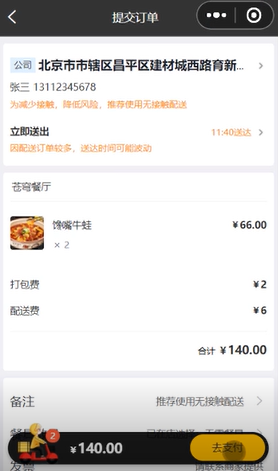 

**去支付：**

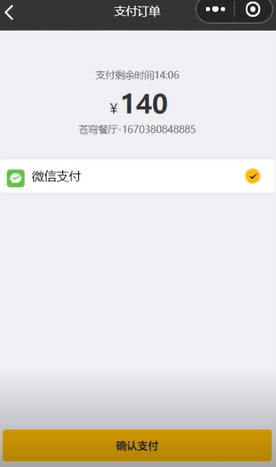 

**确认支付：**

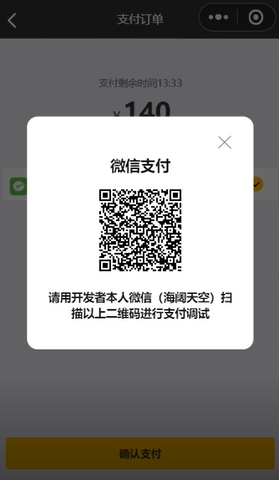 

进行扫码支付即可。


### 支付与通知验收矩阵（补充）

| 场景 | 核对结果 |
| --- | --- |
| 自己的有效待付款订单 | 创建对应预支付单，金额与服务端订单一致 |
| 他人订单、不存在订单 | 发起支付前拒绝 |
| 已支付或不可支付订单 | 按状态拒绝，不重复创建无效支付尝试 |
| 微信下单错误、网络超时 | 明确失败/待确认处理，不伪装成已付款 |
| 真实成功通知 | 验签、解密、订单号、商户、金额均核对后迁移状态 |
| 无签名、错误签名或异常通知体 | 不更新本地订单 |
| 非成功交易状态或金额不符 | 不当作成功支付，按规则处理 |
| 同一通知重复、并发到达 | 仅首次有效迁移，原支付时间与后续状态不被覆盖 |
| 已取消订单收到成功支付确认 | 进入定义的对账/补偿流程，不静默复活 |
| 前端成功、通知延迟 | 前端查后端确认状态，不自行设置已支付 |

需要区分“按协议验证通知的测试”和“直接用Postman伪造成功JSON”。后者没有可信签名，不能用于证明真实支付接入已完成。

具备商户测试条件时按受控测试环境验证小额流程；缺少商户条件时可用隔离的支付适配器替身验证本地订单状态机与失败路径，必须标记为模拟，不能将其称为微信真实付款。

本笔记只完成资料整理与示例检查，未调用微信支付、未扣款、未启动回调穿透，后端业务代码未在你的电脑上运行。


### 3.5 代码提交

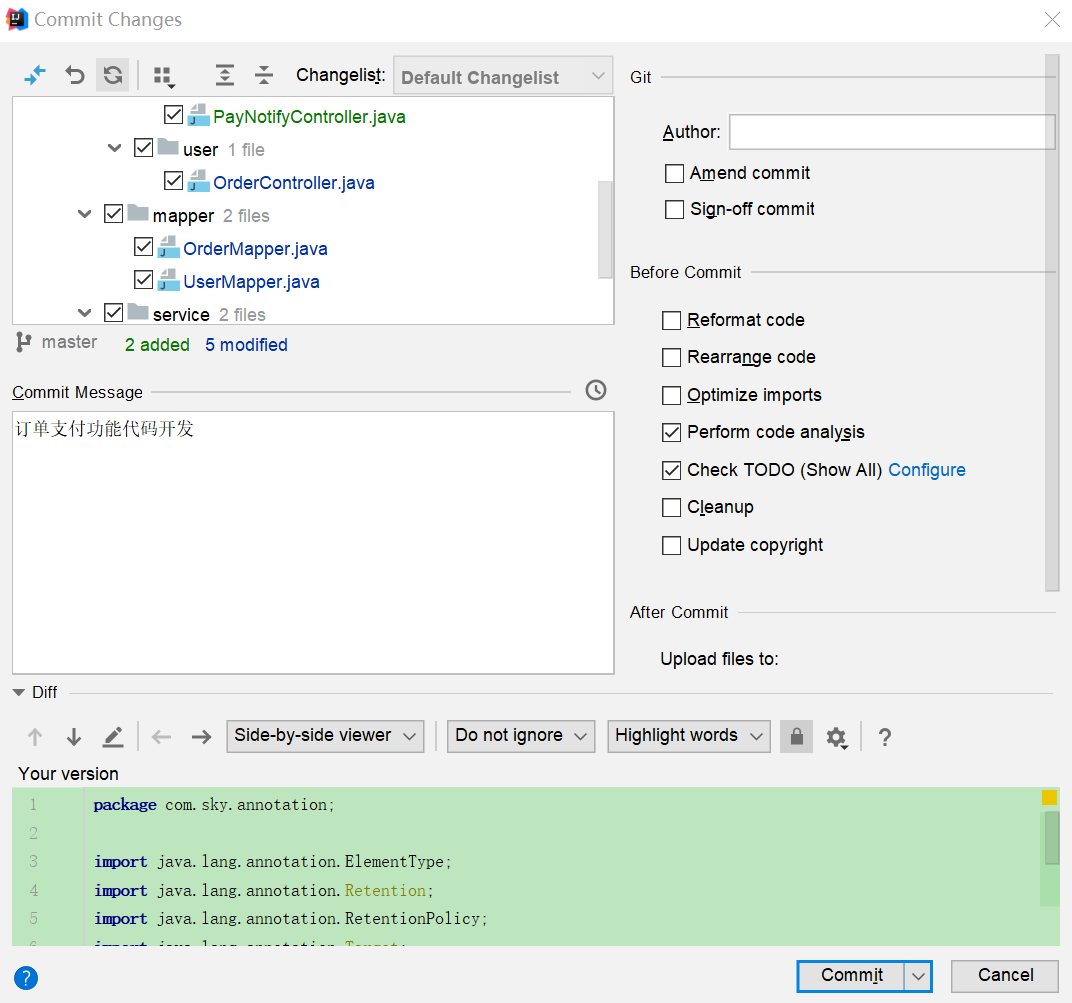 

 后续步骤和其它功能代码提交一致，不再赘述。


## 复习速查与本章验收（补充）

| 知识点 | 核心记忆 |
| --- | --- |
| 地址归属 | 所有按id操作都校验当前用户，列表也不能缺失用户条件 |
| 默认地址 | 验证目标，再事务内清零与设置；并发唯一性另考虑 |
| 订单id与number | id关联明细，number关联支付业务并必须唯一 |
| 金额 | 明细amount单价，订单amount总额，由服务端核算 |
| 快照 | 保存下单时地址与商品信息，不随当前资料改变 |
| 下单事务 | orders、order_detail、购物车处理一起提交/回滚 |
| 幂等 | 唯一订单号不等于同一次结算只提交一次 |
| 预支付 | 生成prepay_id，不表示用户已经支付 |
| 支付金额 | 使用自己订单的已核定金额，不固定0.01元 |
| 回调身份 | 微信服务端通知没有用户JWT，订单号定位已验证交易 |
| 验签与解密 | 来源/完整性验证与内容读取分别执行 |
| 回调幂等 | 限定状态迁移、保存交易关联，不重置已履约状态 |

### 问题排查

| 表现 | 检查方向 |
| --- | --- |
| 列表显示其他人地址 | 当前用户是否缺失、动态user_id条件是否省略 |
| 直接按id能改别人的地址 | get/update/delete是否限定当前用户 |
| 修改省市区后没变化 | 原update漏掉行政区字段 |
| 默认地址多个或消失 | 普通编辑绕过流程、事务失败、并发设置 |
| 下单后orderId为空 | insert主键回填、keyProperty与对象属性 |
| 总金额明显不对 | 是否信任DTO或旧购物车价、单价与数量计算 |
| 明细失败购物车却清空 | 事务代理、异常被吞、操作是否同一事务 |
| 重复订单或新增购物车被误清 | 缺少结算幂等、快照/并发协调 |
| 微信报商户或签名错误 | 应用关联、私钥、序列号、实际SDK配置 |
| 订单几十元却只付一分钱 | 原payment固定测试金额未替换 |
| 微信通知进来后查不到订单 | 原paySuccess依赖不存在的BaseContext用户 |
| 回调签名失败 | 原始body是否被重排、证书/公钥与签名headers |
| 重复回调使订单退回待接单 | 更新缺少前置状态条件与交易幂等 |
| 回调收不到 | notifyUrl完整路径、HTTPS入口、服务可达性 |

### 跟练验收清单

- [ ] 地址七个接口可用，新增和列表身份由服务端确定。
- [ ] 查询、编辑、删除、默认操作都限制当前用户归属。
- [ ] 行政区字段能编辑，默认地址事务与并发策略明确。
- [ ] 下单验证营业状态、地址配送、商品规格、数量和费用。
- [ ] 金额由服务端核算，快照完整，订单号有唯一约束与可靠生成方案。
- [ ] 订单主键回填，明细关联正确，失败时购物车与订单一起回滚。
- [ ] 重复结算与购物车并发修改有明确处理，不只靠@Transactional。
- [ ] 发起支付先查当前用户自己的可支付订单，金额来自该订单。
- [ ] 支付配置使用自己的受控环境，通知地址指向实际/notify/paySuccess。
- [ ] 通知按SDK/协议验签解密，核对商户、订单、状态、金额与币种。
- [ ] 回调不依赖用户BaseContext，重复通知不覆盖后续状态。
- [ ] 支付记录、失败重试与取消后成功付款的对账/补偿规则明确。

### 自测问题

1. 地址列表只显示自己的地址，为什么仍要保护按id修改和删除？
2. 普通地址update允许isDefault=1，会绕过什么规则？
3. 默认地址设置有事务，为什么还需处理并发？
4. orders.id、orders.number、order_detail.order_id如何对应？
5. 为什么不能直接用客户端OrdersSubmitDTO.amount决定应付金额？
6. 下单快照与当前商品、当前地址分别承担什么职责？
7. 明细插入失败时，订单和购物车应怎样变化？
8. 毫秒时间戳能否保证多线程或多实例订单号唯一？
9. 唯一订单号为什么不能防止同一次结算重复提交？
10. 读取购物车后再按userId全删，会怎样影响并发新增？
11. 微信预支付成功是否表示订单已经付款？
12. 微信回调为什么没有当前用户JWT和BaseContext？
13. 原始请求体为什么不能先重写JSON再拿去验签？
14. API v3解密与微信通知签名验证有什么不同？
15. 重复通知为什么不能每次无条件把订单设置为待接单？
16. 本地订单已取消，收到可信成功支付通知后应如何处理？

后续订单管理与超时处理会继续使用本章状态、订单快照和幂等迁移规则；先确认下单、付款确认和履约是不同阶段。
